# Notebook 02 — Preprocessing และ Data Augmentation

**วัตถุประสงค์** ศึกษา preprocessing และ augmentation ที่รักษาลักษณะทางกายภาพของวัสดุและความถูกต้องของ mask เปรียบเทียบแต่ละวิธีกับ baseline ที่ไม่ปรับภาพ ทีละวิธีก่อนรวมกัน และเลือก shortlist สำหรับ Notebook 03 (RQ2, RQ3)

**หลักการ**

1. ใช้ภาพจาก **train เท่านั้น** ในการวิเคราะห์และสร้างข้อมูล ส่วน val ใช้เพียงวัดผลของแบบจำลองเพื่อเลือกวิธี และ test ไม่ถูกโหลดใน notebook นี้ (มีฟังก์ชัน `guard_not_test` ตรวจ)
2. ทดสอบทีละวิธีเทียบกับ baseline ก่อนรวม และให้ทุก arm ฝึกด้วยจำนวน optimizer step เท่ากัน
3. แยก offline transformation (สร้างไฟล์ใหม่) ออกจาก online augmentation (ระหว่างฝึก) อย่างชัดเจน
4. ระดับความแรงของ augmentation อยู่ในช่วงกลาง โดยเทียบกับค่าที่งานวิจัยใช้ (`RESEARCH_PLAN.md` หัวข้อ 8)

**ส่วนที่ใช้เวลานาน** มีเพียงการฝึกในหัวข้อ 7 และ 8 ซึ่งทำงานเมื่อตั้ง `RUN_TRAINING = True` เท่านั้น ส่วนอื่นรันบน CPU ได้ภายในไม่กี่นาที

| ส่วน | ประเภท | เวลาโดยประมาณ |
|---|---|---|
| 0–6 visualization, ตัวชี้วัดคุณภาพภาพ, สร้างชุดข้อมูล offline และ val-C | CPU | 5–10 นาที |
| 7 ablation ของ preprocessing (≤ 2 arm × 1 seed) | **GPU [EXPENSIVE]** | ~25 นาที |
| 8 ablation ของ augmentation (คัดกรอง 9 arm + ยืนยัน 8 run + A9 3 run) | **GPU [EXPENSIVE]** | ~4 ชั่วโมง |

## 0. การตั้งค่า

cell นี้โหลดชุดข้อมูลพัฒนาที่ Notebook 01 สร้างไว้ล่าสุด (จาก `manifests/dataset_versions.json`) และกำหนด flag ที่ควบคุมส่วนที่ใช้เวลานาน

In [1]:
import os, sys, re, json, time, hashlib, platform, subprocess, random, math, shutil, gzip, warnings, contextlib, io
from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import cv2
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon as MplPolygon

warnings.filterwarnings("ignore", category=RuntimeWarning)
SEED = 42
random.seed(SEED); np.random.seed(SEED)

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
assert (ROOT / "RESEARCH_PLAN.md").exists(), f"ROOT ไม่ถูกต้อง: {ROOT}"
CLASS_NAMES = ["gravel", "sand"]
CLASS_COLORS = {"gravel": "#0072B2", "sand": "#E69F00", "mixed": "#999999", "none": "#DDDDDD"}
STATES = ["none", "gravel", "sand", "mixed"]

# ชุดข้อมูลพัฒนาล่าสุดที่ Notebook 01 บันทึกไว้
VERSIONS = json.loads((ROOT / "manifests" / "dataset_versions.json").read_text())
DEV = VERSIONS[-1]
DEV_DIR = ROOT / "data" / f"dev_{DEV['dev_hash']}"
SILVER_DIR = ROOT / "data" / f"silver_{DEV['silver_hash']}"
MANIFEST = pd.read_csv(ROOT / DEV["manifest"])
assert (DEV_DIR / "data.yaml").exists() and (DEV_DIR / "split_meta.json").exists(), "ต้องรัน Notebook 01 ก่อน"
SPLIT_META = json.loads((DEV_DIR / "split_meta.json").read_text())

NOTEBOOK = "02_preprocessing_and_augmentation"
OUT_ROOT = ROOT / "outputs" / "02_preprocessing_augmentation"
OUT_ROOT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.size": 9, "axes.titlesize": 10,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "grid.linewidth": 0.5})

def cfg_hash(d, n=10):
    return hashlib.sha256(json.dumps(d, sort_keys=True, default=str).encode()).hexdigest()[:n]

def sha256_file(p, chunk=1 << 20):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for b in iter(lambda: f.read(chunk), b""):
            h.update(b)
    return h.hexdigest()

def savefig(fig, path_no_ext):
    path_no_ext = Path(path_no_ext); path_no_ext.parent.mkdir(parents=True, exist_ok=True)
    for ext in ("png", "pdf"):
        fig.savefig(f"{path_no_ext}.{ext}", bbox_inches="tight")
    print(f"saved figure: {path_no_ext.relative_to(ROOT)}.png|pdf")

def save_table(df, path, index=False):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    df.to_csv(path, index=index)
    print(f"saved table: {path.relative_to(ROOT)} ({len(df)} rows)")

def split_images(split):
    # คืนรายการภาพของ split พร้อม path ในชุดพัฒนา
    m = MANIFEST[MANIFEST.split == split].copy()
    m["path"] = [str(DEV_DIR / split / "images" / n) for n in m.silver_name]
    m["label_path"] = [str(DEV_DIR / split / "labels" / (Path(n).stem + ".txt")) for n in m.silver_name]
    return m.reset_index(drop=True)

def guard_not_test(paths, allow=False):
    # ป้องกันการโหลดภาพ test ก่อนขั้นประเมินสุดท้าย
    test_dir = str(DEV_DIR / "test")
    bad = [p for p in paths if str(p).startswith(test_dir)]
    if bad and not allow:
        raise PermissionError(f"{len(bad)} test images requested outside the final-evaluation cell")

print("ROOT:", ROOT); print("DEV :", DEV_DIR.relative_to(ROOT), "| silver:", SILVER_DIR.relative_to(ROOT))
print("splits:", SPLIT_META["counts"])

RUN_TRAINING = True           # [EXPENSIVE] ตั้งเป็น True เพื่อฝึกแบบจำลองในหัวข้อ 7–8
BUILD_DATASETS = True         # สร้างชุดข้อมูล offline augmentation และ val-C (CPU)
FIG = OUT_ROOT / "figures"; TAB = OUT_ROOT / "tables"; VIS = OUT_ROOT / "visual_library"
for d in (FIG, TAB, VIS):
    d.mkdir(parents=True, exist_ok=True)
TRAIN = split_images("train"); VAL = split_images("val")
guard_not_test(TRAIN.path); guard_not_test(VAL.path)
print("train", len(TRAIN), "| val", len(VAL))

ROOT: /home/supawich/Desktop/Aggregate_Project/implement/research
DEV : data/dev_19659e679798 | silver: data/silver_0997f3096843
splits: {'train': 714, 'val': 131, 'test': 244}
train 714 | val 131


In [2]:
def pkg_version(name):
    try:
        from importlib.metadata import version
        return version(name)
    except Exception:
        return None

def environment_record():
    rec = dict(timestamp=time.strftime("%Y-%m-%dT%H:%M:%S%z"), python=sys.version.split()[0], platform=platform.platform(),
               cpu=platform.processor(), cpu_count=os.cpu_count(),
               packages={p: pkg_version(p) for p in ["torch", "torchvision", "ultralytics", "numpy", "opencv-python",
                                                     "albumentations", "pycocotools", "onnx", "onnxruntime", "openvino",
                                                     "tensorrt", "nncf", "ncnn", "sahi", "scikit-learn", "scikit-image", "thop",
                                                     "ultralytics-thop"]})
    try:
        import torch
        rec["cuda_available"] = torch.cuda.is_available()
        rec["torch_cuda"] = torch.version.cuda
        rec["cudnn"] = torch.backends.cudnn.version()
        if torch.cuda.is_available():
            p = torch.cuda.get_device_properties(0)
            rec["gpu"] = dict(name=p.name, total_memory_gb=round(p.total_memory / 2**30, 2), capability=f"{p.major}.{p.minor}")
    except Exception as e:
        rec["torch_error"] = str(e)
    try:
        rec["nvidia_smi"] = subprocess.check_output(["nvidia-smi", "--query-gpu=name,driver_version,memory.total",
                                                     "--format=csv,noheader"], text=True).strip()
    except Exception:
        rec["nvidia_smi"] = None
    try:
        rec["git_commit"] = subprocess.check_output(["git", "-C", str(ROOT), "rev-parse", "HEAD"], text=True).strip()
    except Exception:
        rec["git_commit"] = None
    return rec

ENV = environment_record()
(OUT_ROOT / "env_manifest.json").write_text(json.dumps(ENV, indent=2))
print(json.dumps(ENV, indent=2))

{
  "timestamp": "2026-10-18T02:47:04+0700",
  "python": "3.12.3",
  "platform": "Linux-7.0.0-38-generic-x86_64-with-glibc2.39",
  "cpu": "x86_64",
  "cpu_count": 20,
  "packages": {
    "torch": "2.14.1",
    "torchvision": "0.29.1",
    "ultralytics": "8.4.180",
    "numpy": "2.5.4",
    "opencv-python": "5.0.0.93",
    "albumentations": "2.0.8",
    "pycocotools": "2.0.11",
    "onnx": "1.23.2",
    "onnxruntime": "1.31.0",
    "openvino": "2026.4.1",
    "tensorrt": null,
    "nncf": null,
    "ncnn": null,
    "sahi": "0.12.8",
    "scikit-learn": "1.9.1",
    "scikit-image": "0.26.0",
    "thop": null,
    "ultralytics-thop": "2.2.2"
  },
  "cuda_available": true,
  "torch_cuda": "13.0",
  "cudnn": 92400,
  "gpu": {
    "name": "NVIDIA GeForce RTX 3080 Ti",
    "total_memory_gb": 11.62,
    "capability": "8.6"
  },
  "nvidia_smi": "NVIDIA GeForce RTX 3080 Ti, 580.178.04, 12288 MiB",
  "git_commit": "be0a789bbe48419cb657b13060635b565b1376a5"
}


## 1. ชุดภาพตัวอย่างสำหรับการเปรียบเทียบแบบควบคุม

**Method** เลือก 8 ภาพจาก train ด้วยเกณฑ์ที่กำหนดล่วงหน้า: สถานะ (gravel / sand / mixed) × ความสว่าง (ต่ำกว่าหรือสูงกว่า median ของ L\*) เป็น 6 ช่อง แต่ละช่องเลือกภาพที่ค่า L\* ใกล้ median ของช่องนั้นที่สุด และเพิ่มอีก 2 ภาพ คือภาพที่มี instance เล็ก (< 0.1%) มากที่สุด และภาพที่คมชัดน้อยที่สุด (ความแปรปรวนของ Laplacian ต่ำสุด) ทุกภาพต้องมาจากกลุ่มต่างกันถ้าเป็นไปได้

**Rationale** ชุดตัวอย่างคงที่ช่วยให้เปรียบเทียบวิธีต่าง ๆ บนภาพเดียวกันได้ และการเลือกด้วยเกณฑ์ทำให้ทำซ้ำได้และไม่ลำเอียงไปทางภาพที่ดูดี

**Limitation** ภาพ 8 ภาพใช้เพื่อแสดงผลเชิงคุณภาพเท่านั้น ตัวชี้วัดเชิงปริมาณในหัวข้อ 3 คำนวณจาก train ทั้งชุด

In [3]:
def read_yolo(label_path, w, h):
    out = []
    for line in Path(label_path).read_text().splitlines():
        t = line.split()
        if len(t) >= 7:
            out.append((int(t[0]), np.asarray(t[1:], float).reshape(-1, 2) * [w, h]))
    return out

def img_stats_basic(path, short=360):
    bgr = cv2.imread(path)
    lab = cv2.cvtColor(bgr, cv2.COLOR_BGR2LAB).astype(np.float32)
    g = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY); s = short / min(g.shape)
    gs = cv2.resize(g, (round(g.shape[1] * s), round(g.shape[0] * s)), interpolation=cv2.INTER_AREA)
    return dict(L_mean=lab[..., 0].mean() * 100 / 255, lap_var=cv2.Laplacian(gs, cv2.CV_64F).var())

st = pd.DataFrame([img_stats_basic(p) for p in TRAIN.path]); TRAIN = pd.concat([TRAIN, st], axis=1)
TRAIN["n_small"] = [sum(1 for c, p in read_yolo(lp, w, h) if cv2.contourArea(p.astype(np.float32)) / (w * h) < 0.001)
                    for lp, w, h in zip(TRAIN.label_path, TRAIN.width, TRAIN.height)]
L_med = TRAIN.L_mean.median()
picked, used_groups = [], set()
for state in ["gravel", "sand", "mixed"]:
    for bright, cond in [("dark", TRAIN.L_mean < L_med), ("bright", TRAIN.L_mean >= L_med)]:
        cell = TRAIN[(TRAIN.state == state) & cond]
        if cell.empty:
            continue
        med = cell.L_mean.median()
        cand = cell.assign(dist=(cell.L_mean - med).abs()).sort_values("dist")
        fresh = cand[~cand.group_merged.isin(used_groups)]
        row = (fresh if len(fresh) else cand).iloc[0]
        picked.append((f"{state}/{bright}", row.image_id)); used_groups.add(row.group_merged)
for tag, row in [("most-small-instances", TRAIN.sort_values("n_small", ascending=False).iloc[0]),
                 ("least-sharp", TRAIN.sort_values("lap_var").iloc[0])]:
    picked.append((tag, row.image_id))
SAMPLES = pd.DataFrame(picked, columns=["criterion", "image_id"]).merge(TRAIN, on="image_id")
save_table(SAMPLES[["criterion", "image_id", "silver_name", "group_merged", "state", "L_mean", "lap_var", "n_small"]], TAB / "sample_set.csv")
SAMPLES[["criterion", "group_merged", "state", "L_mean", "lap_var", "n_small"]]

saved table: outputs/02_preprocessing_augmentation/tables/sample_set.csv (7 rows)


,criterion,group_merged,state,L_mean,lap_var,n_small
0,gravel/dark,f9b12ec3-0036-45f7-8cc3-4d2e6f481cdc,gravel,67.110565,446.810413,0
1,gravel/bright,e9eebbd1-234c-467a-91b7-690191769c63,gravel,72.293404,318.848042,0
2,sand/dark,2be0c9f6-caf7-4f26-9b59-b1299865a721,sand,69.616928,757.005964,0
3,sand/bright,bbf45eda-4ffb-4bf1-9b29-a4e91475c8ec,sand,71.402008,401.640277,0
4,mixed/dark,1991989f-1bf5-4e50-89bb-7301b220ac01,mixed,67.848320,1268.244854,4
5,most-small-instances,9056e676-f14d-410c-9dc7-c5686b3fca04,gravel,64.209091,4574.075620,6
6,least-sharp,f9b12ec3-0036-45f7-8cc3-4d2e6f481cdc,gravel,63.801956,104.666170,0


In [4]:
def overlay(ax, img_bgr, polys, title=None, alpha=0.35, lw=0.8):
    ax.imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for c, p in polys:
        col = CLASS_COLORS[CLASS_NAMES[c]]
        ax.add_patch(MplPolygon(p, closed=True, facecolor=col, edgecolor=col, alpha=alpha, lw=lw))
    if title:
        ax.set_title(title, fontsize=7)

def comparison_figure(name, fn, title, n=None, show_diff=True):
    # สำหรับแต่ละภาพตัวอย่าง: ต้นฉบับ | หลังแปลง | ผลต่าง | หลังแปลง + polygon
    rows = SAMPLES if n is None else SAMPLES.head(n)
    ncol = 4 if show_diff else 3
    fig, axes = plt.subplots(len(rows), ncol, figsize=(ncol * 2.3, len(rows) * 2.2))
    for r_i, r in enumerate(rows.itertuples()):
        img = cv2.imread(r.path); out = fn(img, np.random.default_rng(SEED + int(r.image_id)))
        polys = read_yolo(r.label_path, r.width, r.height)
        ax = axes[r_i]
        overlay(ax[0], img, [], f"original | {r.criterion}")
        overlay(ax[1], out, [], "transformed")
        if show_diff:
            d = cv2.absdiff(out, img).mean(axis=2)
            ax[2].imshow(d, cmap="magma", vmin=0, vmax=max(d.max(), 1)); ax[2].set_xticks([]); ax[2].set_yticks([]); ax[2].grid(False)
            ax[2].set_title(f"|diff| mean={d.mean():.1f}", fontsize=7)
        overlay(ax[-1], out, polys, "transformed + polygons")
    fig.suptitle(title, fontsize=9); fig.tight_layout(); savefig(fig, VIS / name); plt.show()

## 2. การปรับขนาดภาพและอัตราส่วนภาพ

**Method** เปรียบเทียบ letterbox ของ Ultralytics (ย่อด้านยาวเป็น 640 รักษาอัตราส่วน และเติมขอบสีเทา 114) กับการ resize เป็น 640 × 640 โดยไม่รักษาอัตราส่วน

**Rationale** ภาพในชุดข้อมูลมีอัตราส่วน 9:16 และ 16:9 เป็นส่วนใหญ่ การ resize แบบไม่รักษาอัตราส่วนบิดรูปทรงของกองวัสดุและเนื้อผิวไปในทิศทางเดียว

**Reference** Ultralytics `LetterBox` (`ultralytics/data/augment.py`) ซึ่งเป็น preprocessing มาตรฐานของ predict และ val

**Implementation** วัดอัตราส่วนด้านของ minimum rotated rectangle ของ polygon ก่อนและหลังการแปลง

**Limitation** letterbox ทำให้ภาพแนวตั้งใช้พื้นที่ของ input เพียง 56% ความละเอียดของวัสดุจึงลดลงในภาพแนวตั้ง

saved table: outputs/02_preprocessing_augmentation/tables/resize_aspect_change.csv (1 rows)


,aspect_rel_change_letterbox,aspect_rel_change_squash
orientation,,
portrait,9.907989e-08,0.4684


saved figure: outputs/02_preprocessing_augmentation/visual_library/P0_resize_letterbox_vs_squash.png|pdf


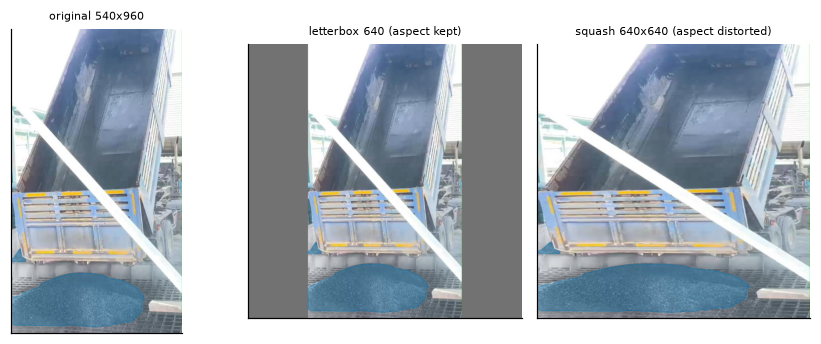

In [5]:
from ultralytics.data.augment import LetterBox
LB = LetterBox(new_shape=(640, 640), auto=False, scaleup=True)

def letterbox_poly(p, w, h, size=640):
    r = min(size / w, size / h); nw, nh = round(w * r), round(h * r)
    return p * r + [(size - nw) / 2, (size - nh) / 2]

def mrr_aspect(p):
    (cx, cy), (a, b), ang = cv2.minAreaRect(p.astype(np.float32))
    return max(a, b) / max(min(a, b), 1e-6)

rows = []
for r in TRAIN.itertuples():
    for c, p in read_yolo(r.label_path, r.width, r.height):
        if len(p) < 3:
            continue
        a0 = mrr_aspect(p)
        a_lb = mrr_aspect(letterbox_poly(p, r.width, r.height))
        a_sq = mrr_aspect(p * [640 / r.width, 640 / r.height])
        rows.append(dict(image_id=r.image_id, orientation="portrait" if r.height > r.width else "landscape",
                         aspect_rel_change_letterbox=abs(a_lb / a0 - 1), aspect_rel_change_squash=abs(a_sq / a0 - 1)))
df_ar = pd.DataFrame(rows)
summary_ar = df_ar.groupby("orientation")[["aspect_rel_change_letterbox", "aspect_rel_change_squash"]].median()
save_table(summary_ar.reset_index(), TAB / "resize_aspect_change.csv")
display(summary_ar)

r = SAMPLES.iloc[0]; img = cv2.imread(r.path); polys = read_yolo(r.label_path, r.width, r.height)
lb = LB(image=img); sq = cv2.resize(img, (640, 640))
fig, ax = plt.subplots(1, 3, figsize=(8, 3.2))
overlay(ax[0], img, polys, f"original {r.width}x{r.height}")
overlay(ax[1], lb, [(c, letterbox_poly(p, r.width, r.height)) for c, p in polys], "letterbox 640 (aspect kept)")
overlay(ax[2], sq, [(c, p * [640 / r.width, 640 / r.height]) for c, p in polys], "squash 640x640 (aspect distorted)")
fig.tight_layout(); savefig(fig, VIS / "P0_resize_letterbox_vs_squash"); plt.show()

## 3. Preprocessing: ทดสอบทีละวิธีเทียบกับภาพดิบ

วิธีที่ทดสอบและแหล่งอ้างอิง

| รหัส | วิธี | พารามิเตอร์ | Reference | ประโยชน์ที่คาดหวัง | ความเสี่ยง |
|---|---|---|---|---|---|
| P1 | Gray-world white balance | สเกลแต่ละช่องสีให้ค่าเฉลี่ยเท่ากัน | Buchsbaum (1980), *J. Franklin Inst.* 310(1): 1–26 [รอตรวจ] | ลดการเอนสีจากแสงต่างแหล่ง | ภาพที่มีวัสดุสีเดียวเต็มภาพ (ทรายสีเหลือง) ถูกดึงสีเข้าหาสีเทา ทำลายสีที่เป็นลักษณะของวัสดุ |
| P2 | CLAHE บนช่อง L ของ CIELAB | clip 2.0, grid 8 × 8 | Zuiderveld (1994), *Graphics Gems IV* [รอตรวจ] | เพิ่ม local contrast ในภาพมืด | ขยาย noise และ artifact ของ JPEG; งานเดิมไม่พบผลดี (val 0.574 เทียบกับ 0.582) |
| P3 | Gamma ปรับ exposure อัตโนมัติ | γ ที่ทำให้ค่าเฉลี่ย L\* เท่ากับ median ของ train | การปรับ gamma มาตรฐาน | ลดความต่างของความสว่างระหว่างแหล่ง | การตัดปลายของ highlight; ไม่แก้ปัญหาแสงไม่สม่ำเสมอภายในภาพ |
| P4 | Non-local means denoising | `fastNlMeansDenoisingColored`, h = 3 | Buades et al. (2005), *CVPR* [รอตรวจ] | ลด sensor noise และ JPEG noise | ทำให้เนื้อผิวของหินและทรายเรียบลง (สูญเสียข้อมูลที่ใช้แยกวัสดุ) |
| P5 | Unsharp masking | σ = 1, amount = 0.5 | วิธีมาตรฐานของการประมวลผลภาพ | เพิ่มความคมของขอบ | ขยาย noise และสร้าง halo |

**เกณฑ์ผ่านที่กำหนดล่วงหน้า** (วัดบน train ทุกภาพ; วิธีที่ผ่านทุกข้อจึงจะทดสอบผลต่อแบบจำลองในหัวข้อ 7)

1. ลดความแปรปรวนระหว่างกลุ่มของสถิติเป้าหมาย (ส่วนเบี่ยงเบนมาตรฐานของค่าเฉลี่ยรายกลุ่มของ L\* สำหรับ P1–P3; ค่าประมาณ noise σ สำหรับ P4; ความแปรปรวนของ Laplacian สำหรับ P5) อย่างน้อย 10%
2. เนื้อผิวในบริเวณวัสดุเปลี่ยนไม่เกิน 10% (การเปลี่ยนแปลงสัมพัทธ์ของ median ของ GLCM homogeneity)
3. สีของบริเวณวัสดุเปลี่ยนไม่เกิน ΔE2000 = 10 (median) ยกเว้น P1 ซึ่งมีจุดประสงค์เพื่อเปลี่ยนสี จึงรายงานโดยไม่ใช้เกณฑ์ข้อนี้
4. สัดส่วนพิกเซลที่ตัดปลาย (0 หรือ 255) เพิ่มขึ้นไม่เกิน 1 จุดร้อยละ

**Limitation** เกณฑ์เหล่านี้วัดคุณสมบัติของภาพ ไม่ได้รับประกันว่าแบบจำลองจะดีขึ้น และภาพไม่มีแผ่นเทียบสี การปรับในหัวข้อนี้จึงไม่ใช่การปรับเทียบสี (color calibration)

saved figure: outputs/02_preprocessing_augmentation/visual_library/P1_grayworld.png|pdf


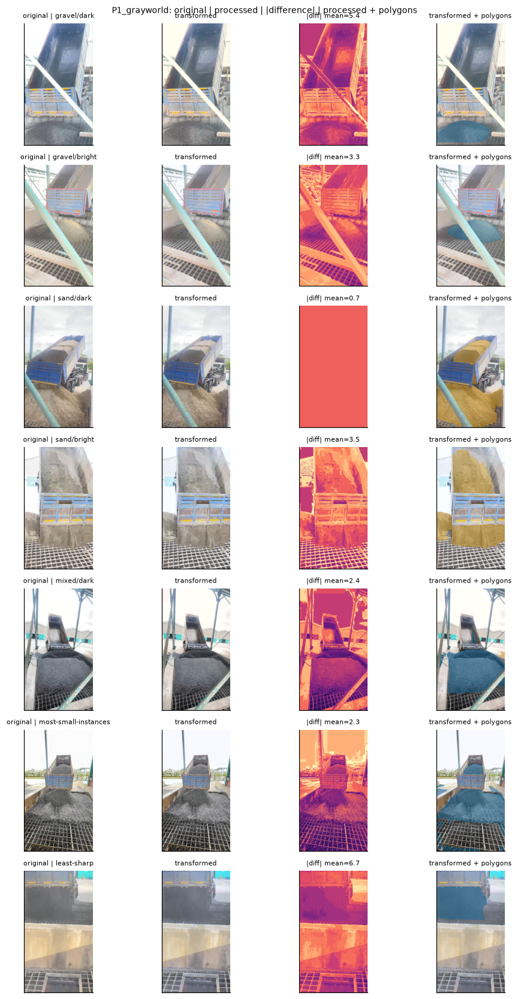

saved figure: outputs/02_preprocessing_augmentation/visual_library/P2_clahe.png|pdf


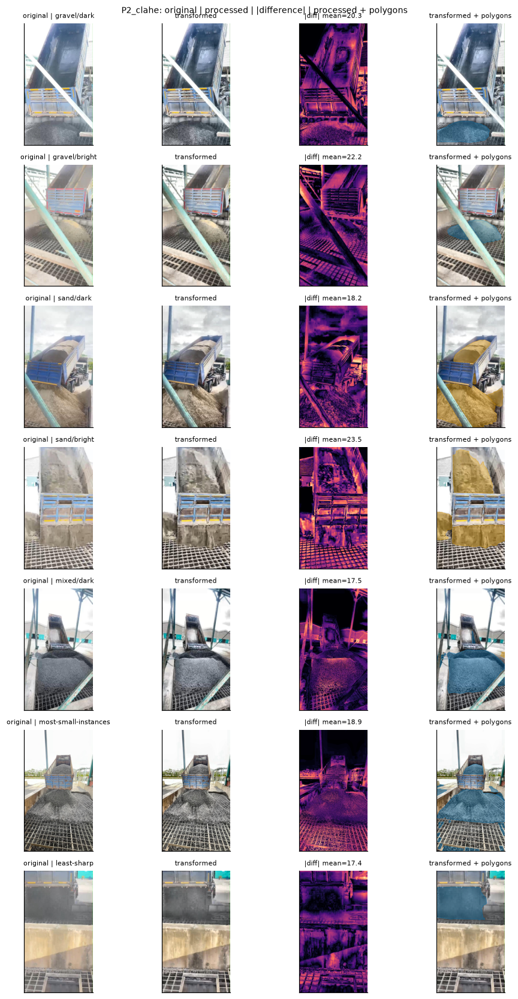

saved figure: outputs/02_preprocessing_augmentation/visual_library/P3_gamma_auto.png|pdf


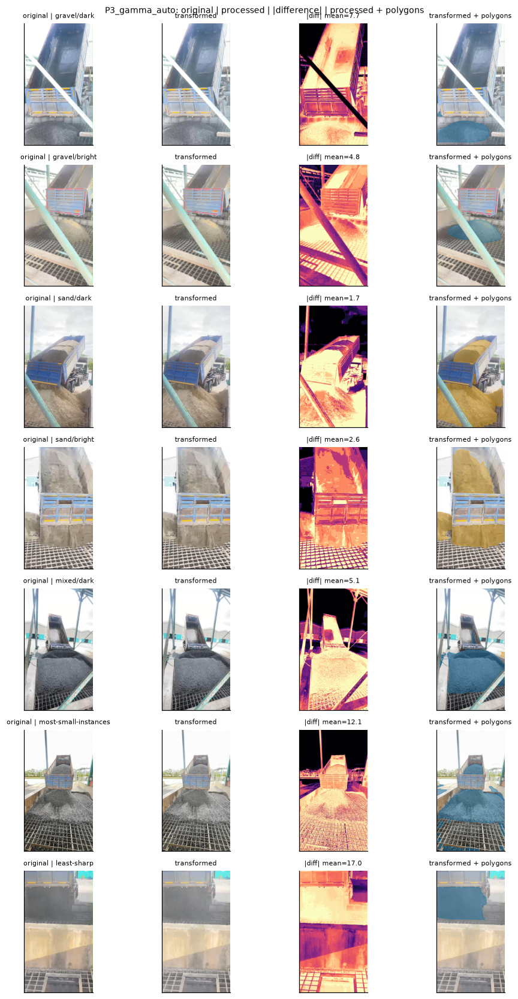

saved figure: outputs/02_preprocessing_augmentation/visual_library/P4_nlmeans.png|pdf


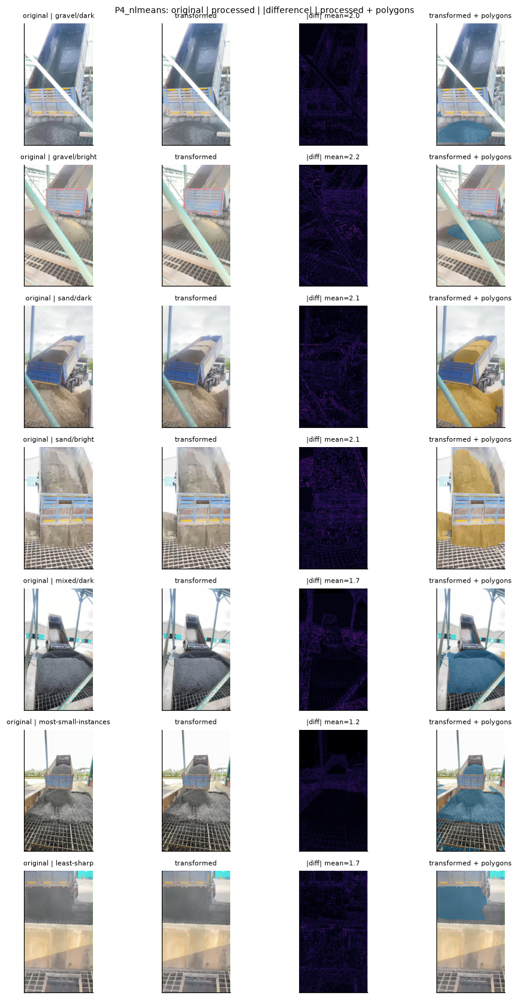

saved figure: outputs/02_preprocessing_augmentation/visual_library/P5_unsharp.png|pdf


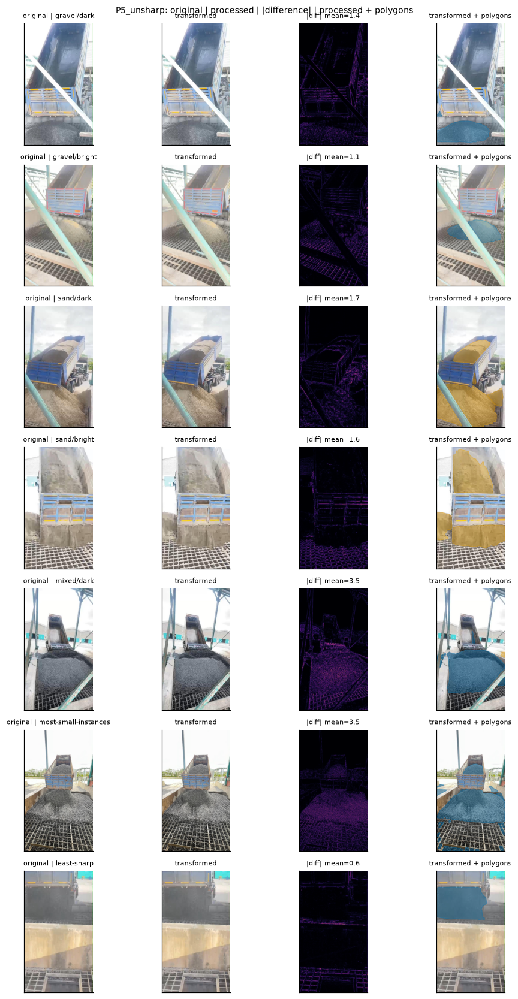

In [6]:
from skimage.feature import graycomatrix, graycoprops
from skimage.color import deltaE_ciede2000
from skimage.restoration import estimate_sigma

TARGET_L = float(TRAIN.L_mean.median())

def pp_grayworld(img, rng=None):
    f = img.astype(np.float32); m = f.reshape(-1, 3).mean(0)
    return np.clip(f * (m.mean() / np.maximum(m, 1e-6)), 0, 255).astype(np.uint8)

def pp_clahe(img, rng=None, clip=2.0, grid=8):
    lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB); l, a, b = cv2.split(lab)
    l = cv2.createCLAHE(clipLimit=clip, tileGridSize=(grid, grid)).apply(l)
    return cv2.cvtColor(cv2.merge([l, a, b]), cv2.COLOR_LAB2BGR)

def pp_gamma_auto(img, rng=None, target=TARGET_L):
    L = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)[..., 0].mean() / 255
    g = np.log(target / 100) / np.log(max(min(L, 0.99), 0.01))
    lut = ((np.arange(256) / 255.0) ** g * 255).clip(0, 255).astype(np.uint8)
    return cv2.LUT(img, lut)

def pp_denoise(img, rng=None, h=3):
    return cv2.fastNlMeansDenoisingColored(img, None, h, h, 7, 21)

def pp_unsharp(img, rng=None, sigma=1.0, amount=0.5):
    blur = cv2.GaussianBlur(img, (0, 0), sigma)
    return cv2.addWeighted(img, 1 + amount, blur, -amount, 0)

PREPROC = {"P1_grayworld": pp_grayworld, "P2_clahe": pp_clahe, "P3_gamma_auto": pp_gamma_auto,
           "P4_nlmeans": pp_denoise, "P5_unsharp": pp_unsharp}
for name, fn in PREPROC.items():
    comparison_figure(name, fn, f"{name}: original | processed | |difference| | processed + polygons")

In [7]:
def material_mask(r):
    m = np.zeros((r.height, r.width), np.uint8)
    for c, p in read_yolo(r.label_path, r.width, r.height):
        cv2.fillPoly(m, [p.astype(np.int32)], 1)
    return m.astype(bool)

def quality(img, mask, short=360):
    g = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    s = short / min(g.shape); gs = cv2.resize(g, (round(g.shape[1] * s), round(g.shape[0] * s)), interpolation=cv2.INTER_AREA)
    ms = cv2.resize(mask.astype(np.uint8), gs.shape[::-1], interpolation=cv2.INTER_NEAREST).astype(bool)
    # GLCM บนบริเวณวัสดุ: ใช้กรอบสี่เหลี่ยมที่ครอบ mask แล้วลดระดับสีเป็น 32 ระดับ
    ys, xs = np.where(ms)
    if len(ys) > 100:
        patch = (gs[ys.min():ys.max() + 1, xs.min():xs.max() + 1] // 8).astype(np.uint8)
        P = graycomatrix(patch, [1], [0, np.pi / 2], levels=32, symmetric=True, normed=True)
        homog = float(graycoprops(P, "homogeneity").mean()); contrast = float(graycoprops(P, "contrast").mean())
    else:
        homog = contrast = np.nan
    lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB).astype(np.float32)
    return dict(L_mean=lab[..., 0].mean() * 100 / 255, lap_var=cv2.Laplacian(gs, cv2.CV_64F).var(),
                noise_sigma=float(estimate_sigma(gs, channel_axis=None)), glcm_homogeneity=homog, glcm_contrast=contrast,
                clip_frac=float(((g == 0) | (g == 255)).mean()))

def lab_float(img):
    return cv2.cvtColor(img.astype(np.float32) / 255, cv2.COLOR_BGR2LAB)

t0 = time.time(); qrows = []
for r in TRAIN.itertuples():
    img = cv2.imread(r.path); mask = material_mask(r)
    base_q = quality(img, mask); base_lab = lab_float(img)
    qrows.append(dict(image_id=r.image_id, group=r.group_merged, method="P0_raw", dE_material=0.0, **base_q))
    for name, fn in PREPROC.items():
        out = fn(img)
        dE = deltaE_ciede2000(base_lab[mask], lab_float(out)[mask]) if mask.any() else np.array([np.nan])
        qrows.append(dict(image_id=r.image_id, group=r.group_merged, method=name, dE_material=float(np.median(dE)), **quality(out, mask)))
DQ = pd.DataFrame(qrows)
print(f"quality metrics for {len(TRAIN)} images x {len(PREPROC)+1} methods in {time.time()-t0:.0f}s")
save_table(DQ, TAB / "preprocessing_quality_per_image.csv")

quality metrics for 714 images x 6 methods in 338s
saved table: outputs/02_preprocessing_augmentation/tables/preprocessing_quality_per_image.csv (4284 rows)


In [8]:
def between_group_sd(df, col):
    return float(df.groupby("group")[col].mean().std())

raw = DQ[DQ.method == "P0_raw"].set_index("image_id")
target_stat = {"P1_grayworld": "L_mean", "P2_clahe": "L_mean", "P3_gamma_auto": "L_mean", "P4_nlmeans": "noise_sigma", "P5_unsharp": "lap_var"}
rows = []
for name in PREPROC:
    d = DQ[DQ.method == name].set_index("image_id")
    tgt = target_stat[name]
    sd0, sd1 = between_group_sd(raw.reset_index(), tgt), between_group_sd(d.reset_index(), tgt)
    if name == "P4_nlmeans":
        improve = 1 - d.noise_sigma.median() / raw.noise_sigma.median()
    elif name == "P5_unsharp":
        improve = d.lap_var.median() / raw.lap_var.median() - 1
    else:
        improve = 1 - sd1 / sd0
    homog_change = abs(d.glcm_homogeneity.median() / raw.glcm_homogeneity.median() - 1)
    dE = d.dE_material.median(); clip_inc = (d.clip_frac.mean() - raw.clip_frac.mean()) * 100
    crit = dict(c1_target_improves_10pct=improve >= 0.10, c2_texture_change_le_10pct=homog_change <= 0.10,
                c3_color_dE_le_10=True if name == "P1_grayworld" else dE <= 10, c4_clipping_increase_le_1pt=clip_inc <= 1.0)
    rows.append(dict(method=name, target_stat=tgt, target_improvement=improve, between_group_sd_raw=sd0, between_group_sd_new=sd1,
                     glcm_homogeneity_rel_change=homog_change, dE2000_material_median=dE, clipping_increase_pct_points=clip_inc,
                     **crit, passes_all=all(crit.values())))
PP_TABLE = pd.DataFrame(rows)
save_table(PP_TABLE, TAB / "preprocessing_method_table.csv")
display(PP_TABLE.round(3))
PP_PASS = PP_TABLE.method[PP_TABLE.passes_all].tolist()
print("methods passing all pre-specified criteria (go to model test in section 7):", PP_PASS)

saved table: outputs/02_preprocessing_augmentation/tables/preprocessing_method_table.csv (5 rows)


,method,target_stat,target_improvement,between_group_sd_raw,between_group_sd_new,glcm_homogeneity_rel_change,dE2000_material_median,clipping_increase_pct_points,c1_target_improves_10pct,c2_texture_change_le_10pct,c3_color_dE_le_10,c4_clipping_increase_le_1pt,passes_all
0,P1_grayworld,L_mean,-0.025,6.692,6.859,0.001,1.544,-5.401,False,True,True,True,False
1,P2_clahe,L_mean,0.273,6.692,4.864,0.204,6.072,0.119,True,False,True,True,False
2,P3_gamma_auto,L_mean,0.894,6.692,0.706,0.002,1.788,-0.189,True,True,True,True,True
3,P4_nlmeans,noise_sigma,0.048,1.084,0.881,0.080,1.182,-5.492,False,True,True,True,False
4,P5_unsharp,lap_var,0.998,1100.021,1429.786,0.083,0.686,0.356,True,True,True,True,True


methods passing all pre-specified criteria (go to model test in section 7): ['P3_gamma_auto', 'P5_unsharp']


saved figure: outputs/02_preprocessing_augmentation/figures/fig01_preprocessing_quality.png|pdf


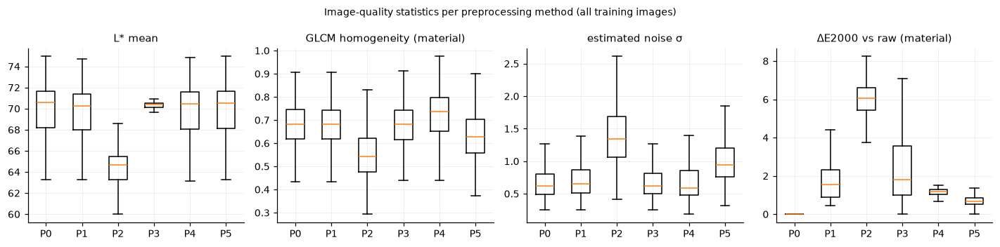

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3.2))
order = ["P0_raw"] + list(PREPROC)
for ax, (col, lab) in zip(axes, [("L_mean", "L* mean"), ("glcm_homogeneity", "GLCM homogeneity (material)"),
                                 ("noise_sigma", "estimated noise σ"), ("dE_material", "ΔE2000 vs raw (material)")]):
    data = [DQ.loc[DQ.method == m, col].dropna() for m in order]
    ax.boxplot(data, showfliers=False); ax.set_xticks(range(1, len(order) + 1), [m.split("_")[0] for m in order]); ax.set_title(lab)
fig.suptitle("Image-quality statistics per preprocessing method (all training images)", fontsize=9)
fig.tight_layout(); savefig(fig, FIG / "fig01_preprocessing_quality"); plt.show()

## 4. ห้องสมุด augmentation: สถานการณ์จำลองและระดับความแรง

ระดับความแรง 1–5 ของแต่ละสถานการณ์กำหนดตามแนวทางของ ImageNet-C และ COCO-C (Hendrycks & Dietterich, 2019, *ICLR*; Michaelis et al., 2019, arXiv:1907.07484) ซึ่งประเมินความทนทานด้วย corruption 5 ระดับ การฝึกใช้ระดับ 1–3 (ระดับกลาง) ส่วนระดับ 4–5 ใช้เฉพาะชุดประเมินความทนทาน val-C

| สถานการณ์ | แบบจำลองของภาพ | ระดับ 1 → 5 | ช่วงที่ใช้ฝึก (ระดับ 1–3) | ค่าอ้างอิงจากงานวิจัย |
|---|---|---|---|---|
| **แสงน้อย** | `I = β·(α·I)^γ` + noise แบบ Poisson–Gaussian | γ = 1.4, 1.8, 2.2, 2.8, 3.5; β = 0.9, 0.8, 0.7, 0.6, 0.5; α ~ U(0.9, 1) | γ 1.4–2.2, β 0.7–0.9 | Lv et al. (arXiv:1908.00682) ใช้ γ ~ U(1.5, 5), β ~ U(0.5, 1), α ~ U(0.9, 1) สำหรับฝึก enhancement |
| **ฝนตก** | เส้นสายฝนเอียง 75–105° + การลด contrast (ม่านฝน) + blur เล็กน้อย | ความหนาแน่น 0.0003–0.002 เส้นต่อพิกเซล, contrast ลด 5–30% | ความหนาแน่น 0.0003–0.0009, contrast ลด 5–15% | Tremblay et al. (2021), *IJCV* 129: 341–360 (rendering ฝนเพื่อประเมินและเพิ่มความทนทาน) |
| **ฝุ่นฟุ้ง** | Koschmieder: `I = J·t + A·(1 − t)` โดย A สีเหลืองน้ำตาล, t ไม่สม่ำเสมอเชิงพื้นที่ (noise ความถี่ต่ำ) และไล่ระดับตามแนวตั้ง | t = 0.85, 0.75, 0.65, 0.5, 0.35 | t 0.65–0.85 | แบบจำลองการกระเจิงแสงที่ใช้สร้าง Foggy Cityscapes (Sakaridis et al., 2018, *IJCV*); ภาพฝุ่นทรายมีการเอนสีเหลืองหรือแดง (Shi et al., 2022, *Sensors*) |

**Limitation ร่วม** ทั้งสามสถานการณ์เป็นแบบจำลองในพื้นที่ภาพ (image space) ไม่ได้จำลองฟิสิกส์ของกล้อง (RAW, ISP) หรือความลึกของฉากจริง ฝนไม่ได้จำลองหยดน้ำบนเลนส์ และฝุ่นใช้ t ที่ไม่ขึ้นกับระยะ ความสมจริงจึงต้องตรวจด้วยตาและยืนยันผลจากข้อมูลจริงใน Notebook 04

In [10]:
SEV = {
    "dark": dict(gamma=[1.4, 1.8, 2.2, 2.8, 3.5], beta=[0.9, 0.8, 0.7, 0.6, 0.5], peak=[600, 400, 250, 150, 80], read=[1.0, 1.5, 2.0, 3.0, 4.0]),
    "rain": dict(density=[0.0003, 0.0006, 0.0009, 0.0014, 0.002], length=[(8, 14), (10, 18), (12, 22), (14, 28), (16, 34)],
                 alpha=[0.35, 0.42, 0.5, 0.55, 0.6], veil=[0.05, 0.10, 0.15, 0.22, 0.30], blur=[0.3, 0.5, 0.7, 0.9, 1.1]),
    "dust": dict(t=[0.85, 0.75, 0.65, 0.5, 0.35], blur=[0.3, 0.5, 0.7, 1.0, 1.3]),
}
DUST_AIRLIGHT_RGB = np.array([196, 174, 138], np.float32)   # สีเหลืองน้ำตาลของฝุ่นทราย (ประมาณจากภาพทรายในชุดข้อมูล)

def _interp(seq, level):
    # level เป็นจำนวนจริงในช่วง [1, 5]; ค่าระหว่างระดับใช้การประมาณเชิงเส้น
    i = np.clip(level, 1, 5) - 1; lo = int(np.floor(i)); hi = min(lo + 1, 4); f = i - lo
    a, b = seq[lo], seq[hi]
    if isinstance(a, tuple):
        return tuple((1 - f) * np.asarray(a) + f * np.asarray(b))
    return (1 - f) * a + f * b

def aug_dark(img, rng, level):
    p = SEV["dark"]; g = _interp(p["gamma"], level); beta = _interp(p["beta"], level); alpha = rng.uniform(0.9, 1.0)
    x = img.astype(np.float32) / 255
    y = beta * (alpha * x) ** g
    peak = _interp(p["peak"], level)
    y = rng.poisson(np.clip(y, 0, 1) * peak) / peak + rng.normal(0, _interp(p["read"], level) / 255, y.shape)
    return (np.clip(y, 0, 1) * 255).astype(np.uint8), dict(gamma=g, beta=beta, alpha=alpha, peak=peak)

def aug_rain(img, rng, level):
    p = SEV["rain"]; h, w = img.shape[:2]; s = h / 640
    n = int(_interp(p["density"], level) * h * w); L0, L1 = _interp(p["length"], level)
    ang = np.deg2rad(rng.uniform(75, 105))
    layer = np.zeros((h, w), np.float32)
    xs, ys = rng.integers(0, w, n), rng.integers(0, h, n); Ls = rng.uniform(L0, L1, n) * s
    for x0, y0, L in zip(xs, ys, Ls):
        cv2.line(layer, (int(x0), int(y0)), (int(x0 + L * np.cos(ang)), int(y0 + L * np.sin(ang))), float(rng.uniform(0.6, 1.0)), 1, cv2.LINE_AA)
    layer = cv2.GaussianBlur(layer, (0, 0), 0.7 * s)
    f = img.astype(np.float32) / 255
    veil = _interp(p["veil"], level)
    f = f * (1 - veil) + veil * f.mean()
    a = _interp(p["alpha"], level)
    f = 1 - (1 - f) * (1 - a * layer[..., None])                # screen blend ของเส้นฝน
    f = cv2.GaussianBlur(f, (0, 0), _interp(p["blur"], level) * s)
    return (np.clip(f, 0, 1) * 255).astype(np.uint8), dict(streaks=n, length=(L0, L1), angle_deg=float(np.rad2deg(ang)), veil=veil, alpha=a)

def aug_dust(img, rng, level):
    p = SEV["dust"]; h, w = img.shape[:2]
    t0 = _interp(p["t"], level)
    lowfreq = cv2.resize(rng.normal(0, 1, (6, 6)).astype(np.float32), (w, h), interpolation=cv2.INTER_CUBIC)
    ramp = np.linspace(-1, 1, h, dtype=np.float32)[:, None] * rng.uniform(0, 0.5)   # ฝุ่นหนาขึ้นด้านล่างหรือด้านบน
    t = np.clip(t0 + 0.05 * lowfreq + 0.1 * (1 - t0) * ramp, 0.05, 1.0)[..., None]
    A = (DUST_AIRLIGHT_RGB[::-1] * rng.uniform(0.95, 1.05, 3)).astype(np.float32)   # BGR
    f = img.astype(np.float32) * t + A * (1 - t)
    f = cv2.GaussianBlur(f, (0, 0), _interp(p["blur"], level))
    return np.clip(f, 0, 255).astype(np.uint8), dict(t_mean=float(t.mean()), airlight_bgr=A.round(1).tolist())

def aug_photometric(img, rng, level=None):
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV).astype(np.float32)
    dh, ds, dv = rng.uniform(-0.015, 0.015) * 180, rng.uniform(-0.3, 0.3), rng.uniform(-0.25, 0.25)
    hsv[..., 0] = (hsv[..., 0] + dh) % 180; hsv[..., 1] *= 1 + ds; hsv[..., 2] *= 1 + dv
    out = cv2.cvtColor(np.clip(hsv, 0, 255).astype(np.uint8), cv2.COLOR_HSV2BGR)
    sigma = rng.uniform(0, 5); out = np.clip(out + rng.normal(0, sigma, out.shape), 0, 255).astype(np.uint8)
    q = int(rng.integers(60, 91)); out = cv2.imdecode(cv2.imencode(".jpg", out, [cv2.IMWRITE_JPEG_QUALITY, q])[1], cv2.IMREAD_COLOR)
    return out, dict(dh=dh, ds=ds, dv=dv, noise_sigma=sigma, jpeg_q=q)

def aug_blur(img, rng, level=None):
    if rng.random() < 0.5:
        k = int(rng.choice([3, 5, 7])); ang = rng.uniform(0, 180)
        kern = np.zeros((k, k), np.float32); kern[k // 2, :] = 1
        kern = cv2.warpAffine(kern, cv2.getRotationMatrix2D((k / 2 - 0.5, k / 2 - 0.5), ang, 1.0), (k, k)); kern /= kern.sum()
        return cv2.filter2D(img, -1, kern), dict(kind="motion", k=k, angle=ang)
    s = rng.uniform(0.1, 1.2)
    return cv2.GaussianBlur(img, (0, 0), s), dict(kind="gaussian", sigma=s)

SCENARIOS = {"dark": aug_dark, "rain": aug_rain, "dust": aug_dust}

saved figure: outputs/02_preprocessing_augmentation/visual_library/A_scenario_dark_levels.png|pdf


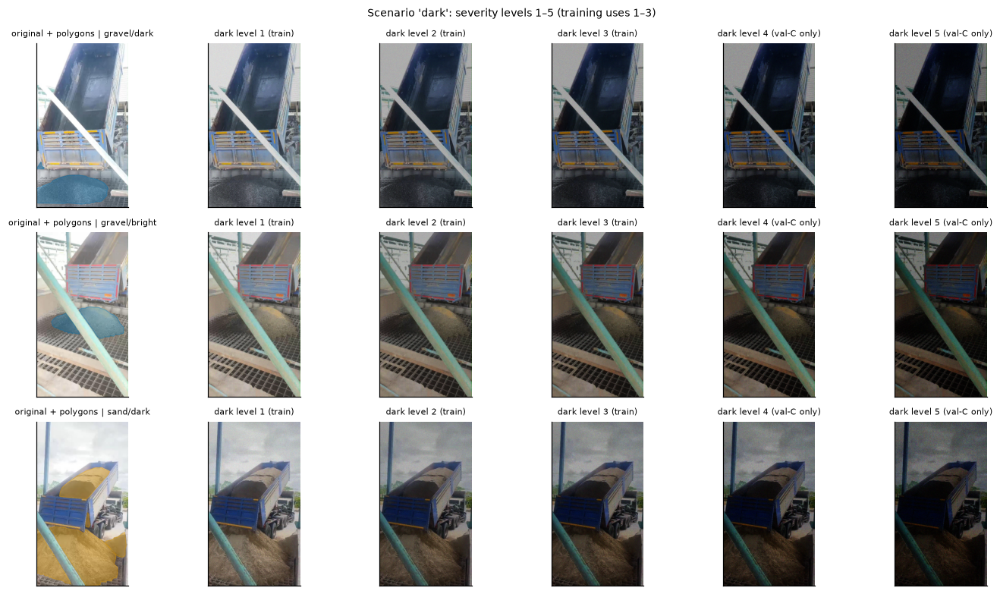

saved figure: outputs/02_preprocessing_augmentation/visual_library/A_scenario_rain_levels.png|pdf


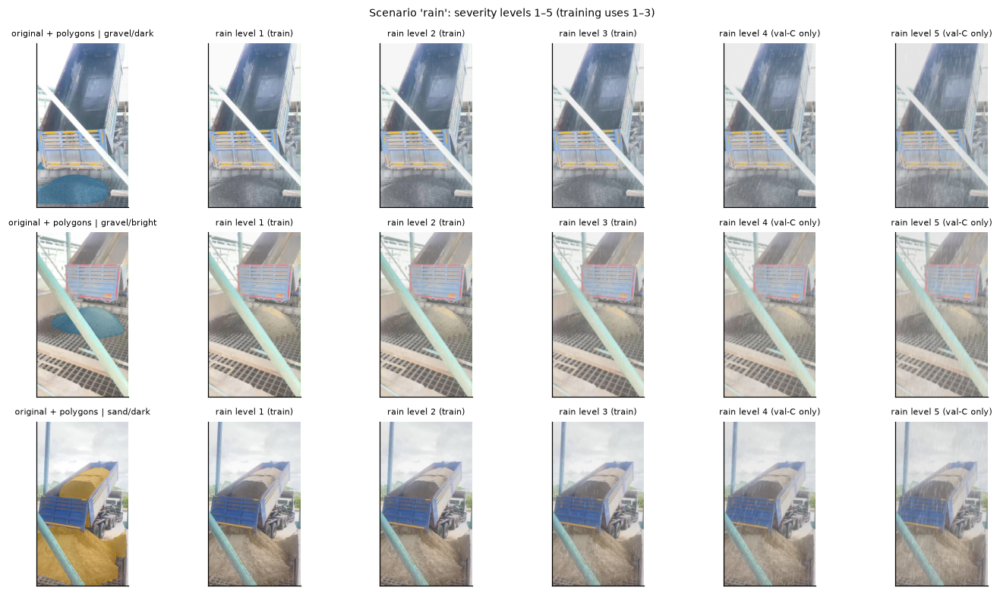

saved figure: outputs/02_preprocessing_augmentation/visual_library/A_scenario_dust_levels.png|pdf


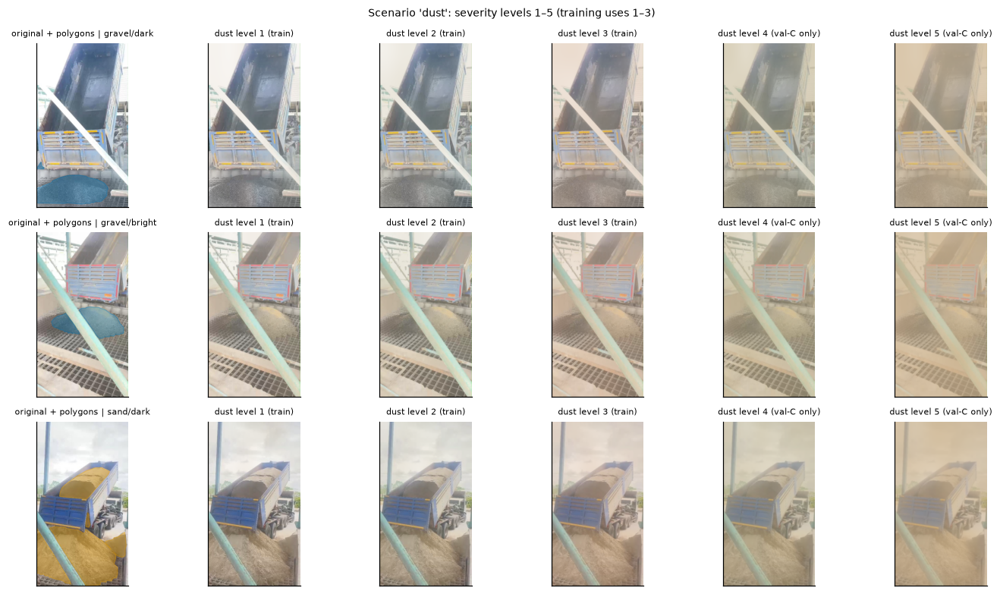

saved figure: outputs/02_preprocessing_augmentation/visual_library/A_offline_rain.png|pdf


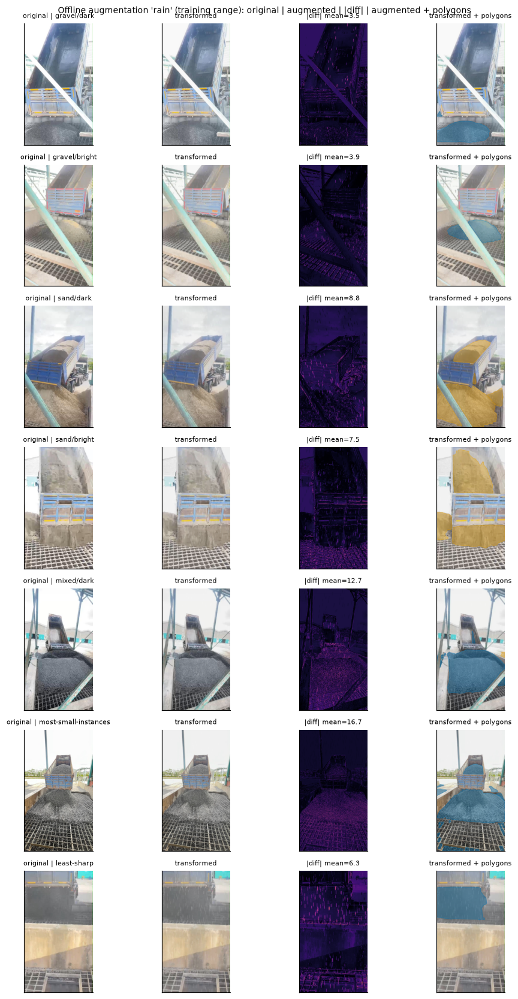

saved figure: outputs/02_preprocessing_augmentation/visual_library/A_offline_dark.png|pdf


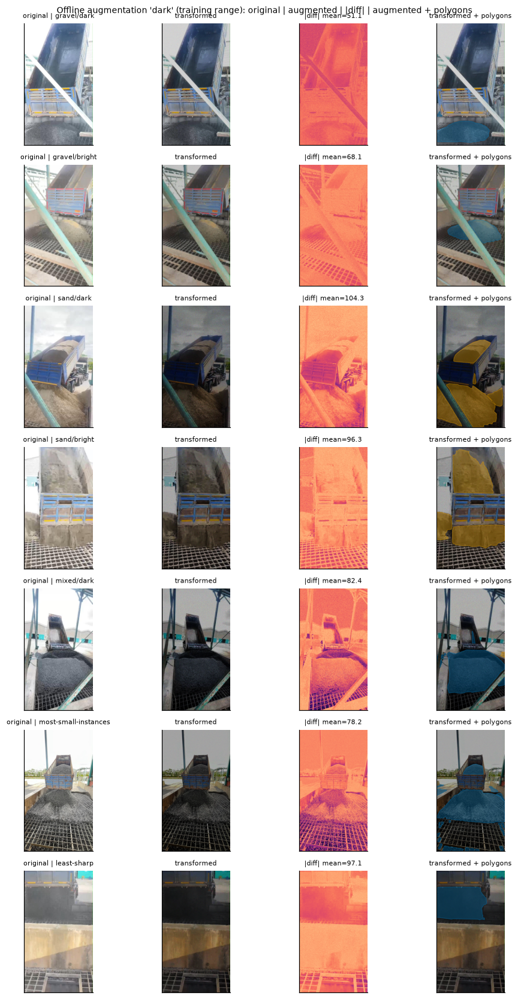

saved figure: outputs/02_preprocessing_augmentation/visual_library/A_offline_dust.png|pdf


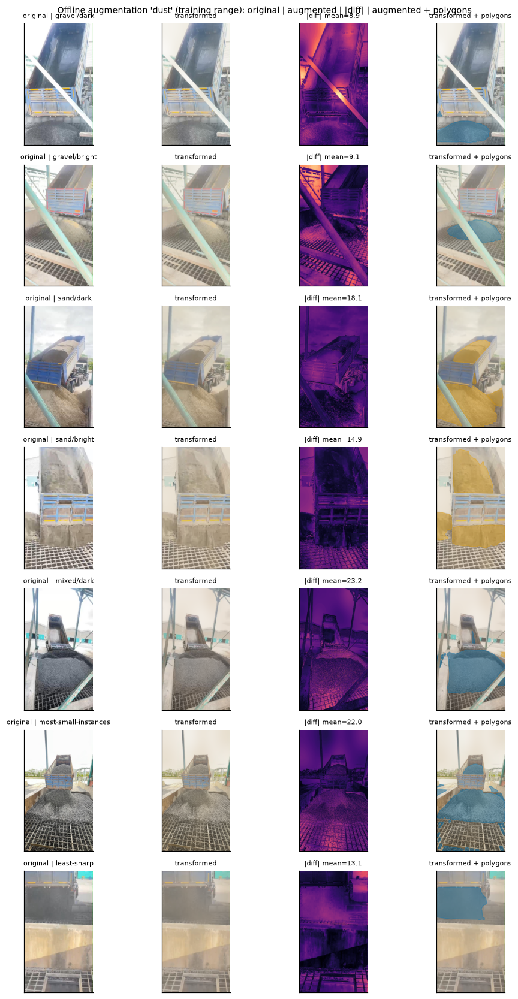

saved figure: outputs/02_preprocessing_augmentation/visual_library/A_offline_photometric.png|pdf


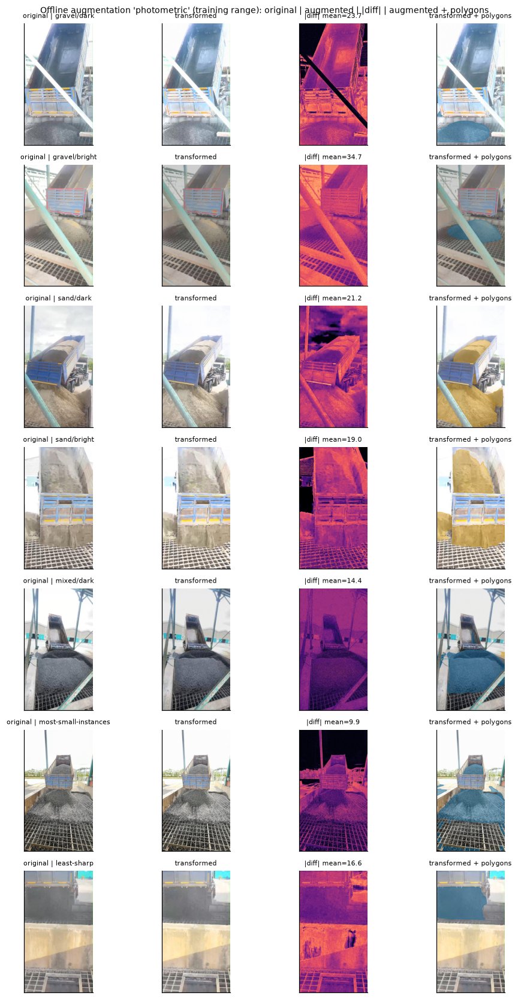

saved figure: outputs/02_preprocessing_augmentation/visual_library/A_offline_blur.png|pdf


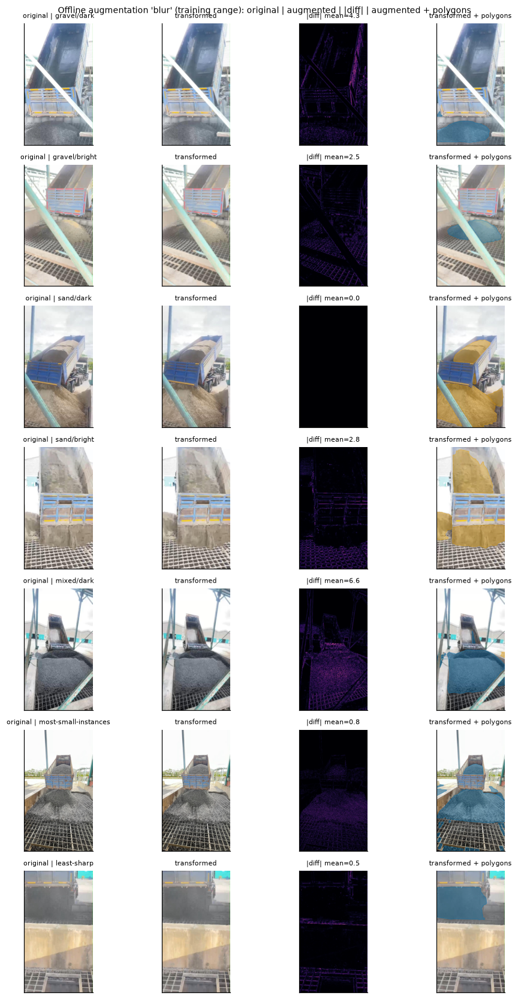

In [11]:
# ภาพของทุกสถานการณ์ที่ระดับ 1–5 บนภาพตัวอย่าง 3 ภาพ (seed คงที่)
for scen, fn in SCENARIOS.items():
    rows3 = SAMPLES.head(3)
    fig, axes = plt.subplots(len(rows3), 6, figsize=(13, 2.4 * len(rows3)))
    for i, r in enumerate(rows3.itertuples()):
        img = cv2.imread(r.path); polys = read_yolo(r.label_path, r.width, r.height)
        overlay(axes[i, 0], img, polys, f"original + polygons | {r.criterion}")
        for lv in range(1, 6):
            out, _ = fn(img, np.random.default_rng(SEED + lv), lv)
            overlay(axes[i, lv], out, [], f"{scen} level {lv}" + (" (train)" if lv <= 3 else " (val-C only)"))
    fig.suptitle(f"Scenario '{scen}': severity levels 1–5 (training uses 1–3)", fontsize=9)
    fig.tight_layout(); savefig(fig, VIS / f"A_scenario_{scen}_levels"); plt.show()

for name, fn in [("rain", lambda im, rng: aug_rain(im, rng, rng.uniform(1, 3))[0]),
                 ("dark", lambda im, rng: aug_dark(im, rng, rng.uniform(1, 3))[0]),
                 ("dust", lambda im, rng: aug_dust(im, rng, rng.uniform(1, 3))[0]),
                 ("photometric", lambda im, rng: aug_photometric(im, rng)[0]),
                 ("blur", lambda im, rng: aug_blur(im, rng)[0])]:
    comparison_figure(f"A_offline_{name}", fn, f"Offline augmentation '{name}' (training range): original | augmented | |diff| | augmented + polygons")

saved figure: outputs/02_preprocessing_augmentation/figures/fig02_scenarios_vs_real_stats.png|pdf


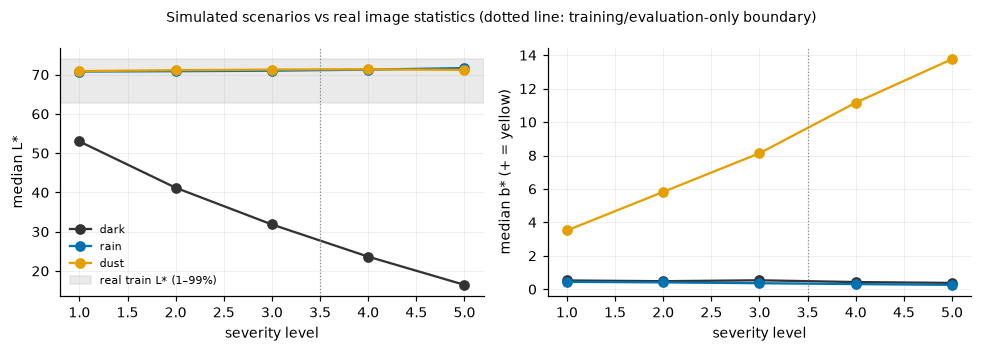

saved table: outputs/02_preprocessing_augmentation/tables/scenario_level_stats.csv (15 rows)


In [12]:
# สถิติภาพจริงของชุดพัฒนาเทียบกับภาพจำลอง: ระดับที่ใช้ฝึกควรอยู่ในหรือใกล้ช่วงที่พบในภาพจริง
real_L = TRAIN.L_mean.values
sim = []
rng = np.random.default_rng(SEED)
sub = TRAIN.sample(60, random_state=SEED)
for r in sub.itertuples():
    img = cv2.imread(r.path)
    for scen, fn in SCENARIOS.items():
        for lv in range(1, 6):
            out, _ = fn(img, rng, lv)
            lab = cv2.cvtColor(out, cv2.COLOR_BGR2LAB).astype(np.float32)
            sim.append(dict(scenario=scen, level=lv, L_mean=lab[..., 0].mean() * 100 / 255, b_mean=lab[..., 2].mean() - 128))
SIM = pd.DataFrame(sim)
fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
for scen, col in zip(SCENARIOS, ["#333333", "#0072B2", "#E69F00"]):
    m = SIM[SIM.scenario == scen].groupby("level").L_mean.median()
    ax[0].plot(m.index, m.values, marker="o", color=col, label=scen)
    mb = SIM[SIM.scenario == scen].groupby("level").b_mean.median()
    ax[1].plot(mb.index, mb.values, marker="o", color=col, label=scen)
ax[0].axhspan(np.percentile(real_L, 1), np.percentile(real_L, 99), color="#cccccc", alpha=0.4, label="real train L* (1–99%)")
ax[0].axvline(3.5, color="#888888", ls=":", lw=0.8); ax[1].axvline(3.5, color="#888888", ls=":", lw=0.8)
ax[0].set_xlabel("severity level"); ax[0].set_ylabel("median L*"); ax[0].legend(frameon=False, fontsize=7)
ax[1].set_xlabel("severity level"); ax[1].set_ylabel("median b* (+ = yellow)")
fig.suptitle("Simulated scenarios vs real image statistics (dotted line: training/evaluation-only boundary)", fontsize=9)
fig.tight_layout(); savefig(fig, FIG / "fig02_scenarios_vs_real_stats"); plt.show()
save_table(SIM.groupby(["scenario", "level"]).median().reset_index(), TAB / "scenario_level_stats.csv")

## 5. Online augmentation ของ Ultralytics: ภาพจริงจาก pipeline ที่ใช้ฝึก

**Method** สร้าง dataset ของ Ultralytics (`build_yolo_dataset`, mode='train') โดยเปิด augmentation ทีละชนิด (ชนิดอื่นปิดทั้งหมด) แล้วดึงภาพและ mask ที่ pipeline คืนมาจริง พร้อมตรวจความสอดคล้องระหว่าง mask กับ bounding box ที่ pipeline สร้าง (IoU ระหว่างกรอบที่คำนวณจาก mask กับกรอบของ label)

| ชนิด | ค่าที่แสดง | Reference | ความเหมาะสมกับงานนี้ |
|---|---|---|---|
| HSV | hsv_h 0.015, hsv_s 0.7, hsv_v 0.4 (ค่าเริ่มต้น) | Ultralytics docs | สมเหตุสมผลกับการเปลี่ยนแสงและกล้อง แต่ hue ที่เปลี่ยนมากเกินไปอาจทำให้สีทรายคล้ายสีอื่น |
| Flip แนวนอน | fliplr 0.5 | Ultralytics docs | สมเหตุสมผล กล้องอาจติดตั้งได้ทั้งสองด้านของรถ |
| Flip แนวตั้ง | ไม่ใช้ | — | ไม่สมเหตุสมผลทางกายภาพ วัสดุตกจากบนลงล่างตามแรงโน้มถ่วง และตะแกรงอยู่ด้านล่างของภาพเสมอ |
| หมุน | ±10° | Ultralytics docs | มุมกล้องคลาดเคลื่อนเล็กน้อยระหว่างจุดติดตั้ง |
| Translate / scale | 0.1 / 0.5 (ค่าเริ่มต้น) | Ultralytics docs | ระยะและตำแหน่งของรถต่างกันในแต่ละครั้ง |
| Mosaic | 1.0 (ปิด 10 epoch สุดท้าย) | Bochkovskiy et al. (2020), arXiv:2004.10934 [รอตรวจ] | สร้างบริบทใหม่และเพิ่มจำนวน instance ต่อภาพ แต่สร้างฉากที่ไม่มีจริง |
| Copy-Paste | 0.3, mode flip | Ghiasi et al. (2021), *CVPR* | วางวัสดุข้ามฉาก ช่วยลดความผูกพันระหว่างวัสดุกับฉาก (Cramér's V = 0.98 ใน Notebook 01) |
| MixUp | ไม่ใช้ | Zhang et al. (2018), *ICLR* [รอตรวจ] | การผสมภาพสองภาพแบบโปร่งใสสร้างเนื้อผิวที่ไม่มีจริงของวัสดุ |

**Limitation** การตรวจความสอดคล้องของ mask ทำกับตัวอย่างจำนวนจำกัด และใช้ implementation ของ Ultralytics ตามที่ติดตั้ง

train: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4037.4±1576.1 MB/s, size: 43.7 KB)


train: Scanning /home/supawich/Desktop/Aggregate_Project/implement/research/data/dev_19659e679798/train/labels.cache... 714 images, 5 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 714/714 249.6Mit/s 0.0s

albumentations: Blur(p=0.01, blur_limit=(3, 7)), MedianBlur(p=0.01, blur_limit=(3, 7)), ToGray(p=0.01, method='weighted_average', num_output_channels=3), CLAHE(p=0.01, clip_limit=(1.0, 4.0), tile_grid_size=(8, 8))


saved figure: outputs/02_preprocessing_augmentation/visual_library/U_online_hsv_default.png|pdf


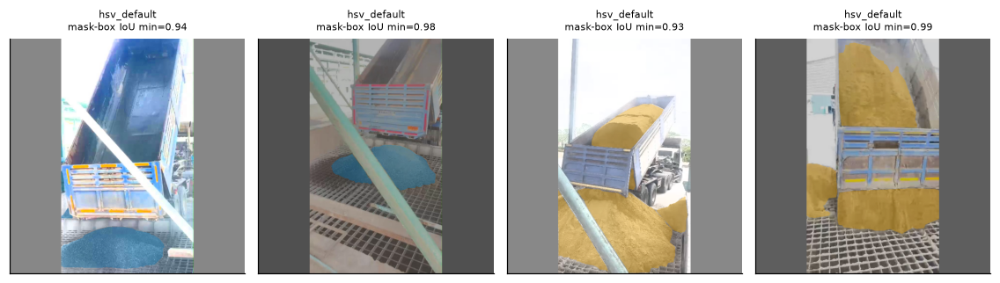

train: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4623.1±1869.3 MB/s, size: 43.2 KB)


train: Scanning /home/supawich/Desktop/Aggregate_Project/implement/research/data/dev_19659e679798/train/labels.cache... 714 images, 5 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 714/714 249.6Mit/s 0.0s

albumentations: Blur(p=0.01, blur_limit=(3, 7)), MedianBlur(p=0.01, blur_limit=(3, 7)), ToGray(p=0.01, method='weighted_average', num_output_channels=3), CLAHE(p=0.01, clip_limit=(1.0, 4.0), tile_grid_size=(8, 8))


saved figure: outputs/02_preprocessing_augmentation/visual_library/U_online_fliplr.png|pdf


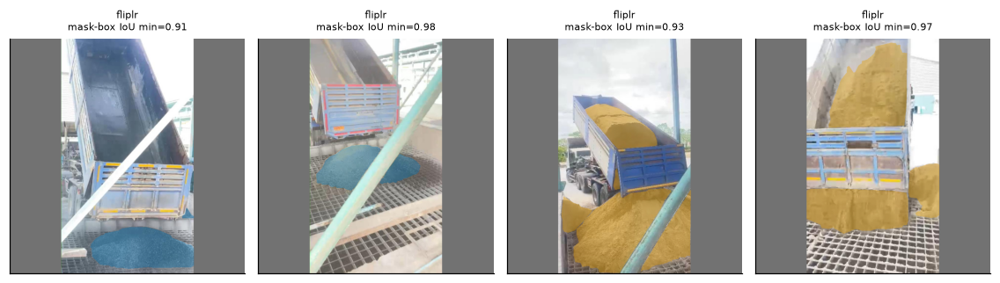

train: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4477.2±1690.9 MB/s, size: 43.2 KB)


train: Scanning /home/supawich/Desktop/Aggregate_Project/implement/research/data/dev_19659e679798/train/labels.cache... 714 images, 5 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 714/714 598.9Mit/s 0.0s

albumentations: Blur(p=0.01, blur_limit=(3, 7)), MedianBlur(p=0.01, blur_limit=(3, 7)), ToGray(p=0.01, method='weighted_average', num_output_channels=3), CLAHE(p=0.01, clip_limit=(1.0, 4.0), tile_grid_size=(8, 8))


saved figure: outputs/02_preprocessing_augmentation/visual_library/U_online_rotate_10deg.png|pdf


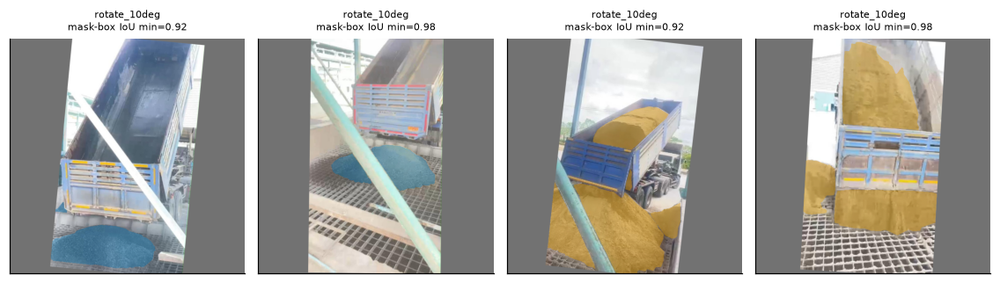

train: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4074.9±1650.3 MB/s, size: 43.2 KB)


train: Scanning /home/supawich/Desktop/Aggregate_Project/implement/research/data/dev_19659e679798/train/labels.cache... 714 images, 5 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 714/714 499.1Mit/s 0.0s

albumentations: Blur(p=0.01, blur_limit=(3, 7)), MedianBlur(p=0.01, blur_limit=(3, 7)), ToGray(p=0.01, method='weighted_average', num_output_channels=3), CLAHE(p=0.01, clip_limit=(1.0, 4.0), tile_grid_size=(8, 8))


saved figure: outputs/02_preprocessing_augmentation/visual_library/U_online_translate_scale_default.png|pdf


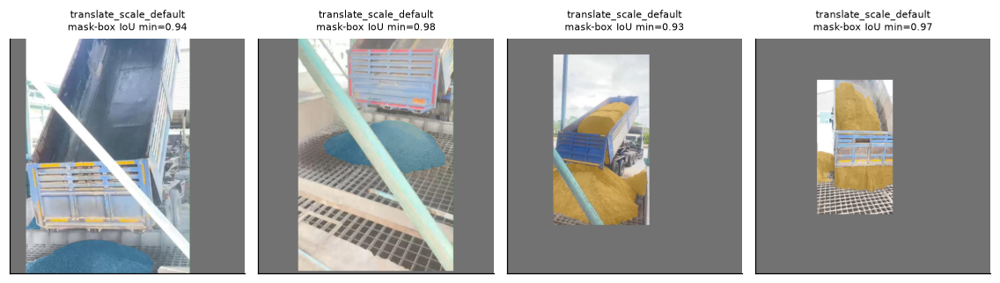

train: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4058.5±1603.9 MB/s, size: 43.2 KB)


train: Scanning /home/supawich/Desktop/Aggregate_Project/implement/research/data/dev_19659e679798/train/labels.cache... 714 images, 5 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 714/714 598.9Mit/s 0.0s

albumentations: Blur(p=0.01, blur_limit=(3, 7)), MedianBlur(p=0.01, blur_limit=(3, 7)), ToGray(p=0.01, method='weighted_average', num_output_channels=3), CLAHE(p=0.01, clip_limit=(1.0, 4.0), tile_grid_size=(8, 8))


saved figure: outputs/02_preprocessing_augmentation/visual_library/U_online_mosaic.png|pdf


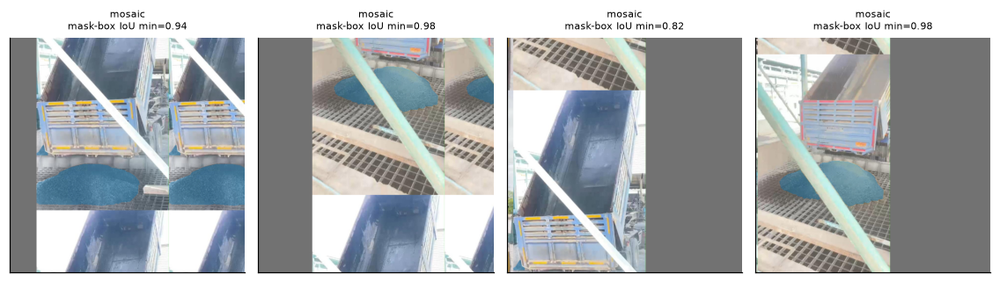

train: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3121.6±972.6 MB/s, size: 36.6 KB)


train: Scanning /home/supawich/Desktop/Aggregate_Project/implement/research/data/dev_19659e679798/train/labels.cache... 714 images, 5 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 714/714 598.9Mit/s 0.0s

albumentations: Blur(p=0.01, blur_limit=(3, 7)), MedianBlur(p=0.01, blur_limit=(3, 7)), ToGray(p=0.01, method='weighted_average', num_output_channels=3), CLAHE(p=0.01, clip_limit=(1.0, 4.0), tile_grid_size=(8, 8))


saved figure: outputs/02_preprocessing_augmentation/visual_library/U_online_copy_paste_0.3.png|pdf


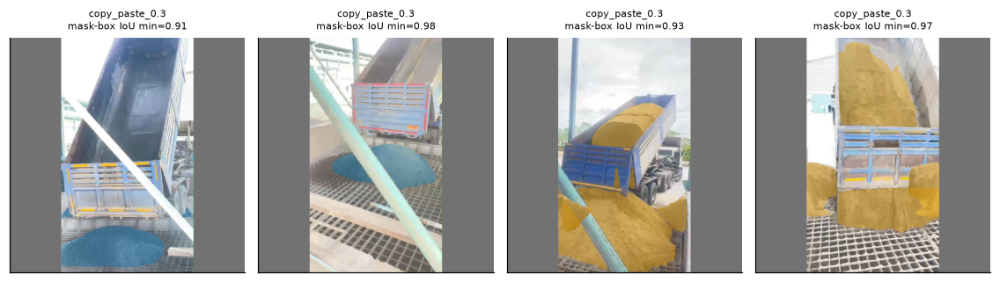

saved table: outputs/02_preprocessing_augmentation/tables/online_aug_mask_box_consistency.csv (6 rows)


,count,mean,std,min,5%,50%,max
augmentation,,,,,,,
copy_paste_0.3,16.0,0.972,0.028,0.913,0.924,0.984,1.000
fliplr,12.0,0.976,0.027,0.913,0.921,0.988,1.000
hsv_default,12.0,0.979,0.022,0.928,0.936,0.986,1.000
mosaic,12.0,0.954,0.053,0.815,0.862,0.978,0.994
rotate_10deg,12.0,0.974,0.026,0.918,0.921,0.984,0.994
translate_scale_default,12.0,0.973,0.020,0.928,0.936,0.980,0.992


In [13]:
import torch
from ultralytics.cfg import get_cfg
from ultralytics.data import build_yolo_dataset
from ultralytics.data.utils import check_det_dataset

DATA_DICT = check_det_dataset(str(DEV_DIR / "data.yaml"))
BASE_OFF = dict(hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, degrees=0.0, translate=0.0, scale=0.0, shear=0.0, perspective=0.0,
                flipud=0.0, fliplr=0.0, bgr=0.0, mosaic=0.0, mixup=0.0, cutmix=0.0, copy_paste=0.0)
ONLINE_VIS = {
    "hsv_default": dict(hsv_h=0.015, hsv_s=0.7, hsv_v=0.4),
    "fliplr": dict(fliplr=1.0),
    "rotate_10deg": dict(degrees=10.0),
    "translate_scale_default": dict(translate=0.1, scale=0.5),
    "mosaic": dict(mosaic=1.0),
    "copy_paste_0.3": dict(copy_paste=1.0),     # p=1 สำหรับการแสดงผลเท่านั้น
}

def ultra_samples(overrides, n=4, seed=SEED):
    cfg = get_cfg(overrides=dict(task="segment", mode="train", imgsz=640, mask_ratio=1, overlap_mask=False, **{**BASE_OFF, **overrides}))
    ds = build_yolo_dataset(cfg, DATA_DICT["train"], batch=8, data=DATA_DICT, mode="train", rect=False, stride=32)
    out = []
    for k, idx in enumerate(SAMPLES.image_id.head(n)):
        i = int(np.where(np.array([Path(f).name for f in ds.im_files]) == MANIFEST.silver_name[MANIFEST.image_id == idx].iloc[0])[0][0])
        random.seed(seed + k); np.random.seed(seed + k); torch.manual_seed(seed + k)
        out.append(ds[i])
    return out

def mask_box_consistency(sample):
    m = sample["masks"].numpy(); b = sample["bboxes"].numpy(); H, W = m.shape[-2:]
    ious = []
    for j in range(min(len(m), len(b))):
        ys, xs = np.where(m[j] > 0)
        if len(xs) == 0:
            continue
        mb = np.array([xs.min(), ys.min(), xs.max() + 1, ys.max() + 1], float)
        cx, cy, bw, bh = b[j] * [W, H, W, H]; lb = np.array([cx - bw / 2, cy - bh / 2, cx + bw / 2, cy + bh / 2])
        ix = max(0, min(mb[2], lb[2]) - max(mb[0], lb[0])); iy = max(0, min(mb[3], lb[3]) - max(mb[1], lb[1]))
        u = (mb[2] - mb[0]) * (mb[3] - mb[1]) + (lb[2] - lb[0]) * (lb[3] - lb[1]) - ix * iy
        ious.append(ix * iy / max(u, 1e-9))
    return ious

cons_rows = []
for name, ov in ONLINE_VIS.items():
    samples = ultra_samples(ov)
    fig, axes = plt.subplots(1, len(samples), figsize=(2.6 * len(samples), 3.0))
    for ax, s in zip(axes, samples):
        img = s["img"].numpy().transpose(1, 2, 0).copy()        # RGB
        ax.imshow(img); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        for j, mj in enumerate(s["masks"].numpy()):
            c = int(s["cls"][j]) if j < len(s["cls"]) else 0
            col = np.array(matplotlib.colors.to_rgb(CLASS_COLORS[CLASS_NAMES[c]]))
            rgba = np.zeros((*mj.shape, 4)); rgba[mj > 0] = [*col, 0.4]
            ax.imshow(rgba)
        ious = mask_box_consistency(s)
        cons_rows += [dict(augmentation=name, iou=v) for v in ious]
        ax.set_title(f"{name}\nmask-box IoU min={min(ious):.2f}" if ious else name, fontsize=7)
    fig.tight_layout(); savefig(fig, VIS / f"U_online_{name}"); plt.show()
CONS = pd.DataFrame(cons_rows)
cons_tab = CONS.groupby("augmentation").iou.describe(percentiles=[0.05, 0.5])
save_table(cons_tab.reset_index(), TAB / "online_aug_mask_box_consistency.csv")
display(cons_tab.round(3))

## 6. การสร้างชุดข้อมูล offline augmentation และชุดประเมินความทนทาน val-C

**Method**

- **Offline augmentation:** สร้างสำเนาของภาพ train ที่ผ่าน augmentation แบบ photometric เท่านั้น polygon จึงไม่เปลี่ยน (คัดลอก label เดิม และตรวจว่าไฟล์ label ตรงกันทุกไบต์) ระดับความแรงสุ่มแบบต่อเนื่องในช่วง 1–3 ด้วย seed ที่ได้จาก hash ของ (arm, ชื่อภาพ) และบันทึกพารามิเตอร์ของทุกภาพ ภาพที่สร้างขึ้นอยู่ในกลุ่มเดียวกับภาพต้นฉบับ และอยู่เฉพาะใน train
- **val-C:** นำภาพ val ทุกภาพผ่านฝน แสงน้อย และฝุ่น ที่ระดับ 1–5 (15 ชุด) ใช้วัด mPC (mean performance under corruption) และ relative robustness (mPC / AP_clean) ตาม Michaelis et al. (2019)

| Arm | ชุดข้อมูล train | จำนวน variant ต่อภาพ (K) |
|---|---|---|
| A3 | photometric ทั่วไป + blur | 1 |
| A4 | ฝน | 1 |
| A5 | แสงน้อย | 1 |
| A6 | ฝุ่น | 1 |
| A7 | ฝน + แสงน้อย + ฝุ่น (สถานการณ์ละหนึ่ง variant) | 3 |

**Limitation** val-C ใช้ตัวสร้างภาพตัวเดียวกับ offline augmentation ผลของ arm A4–A7 บน val-C จึงมีแนวโน้มสูงกว่าความทนทานต่อสภาพจริง

In [14]:
def seed_for(*parts):
    return int(hashlib.sha256("|".join(map(str, parts)).encode()).hexdigest()[:8], 16)

OFFLINE_ARMS = {
    "A3_photometric": [("photometric", lambda im, rng: aug_blur(aug_photometric(im, rng)[0], rng) if rng.random() < 0.5 else aug_photometric(im, rng))],
    "A4_rain": [("rain", lambda im, rng: aug_rain(im, rng, rng.uniform(1, 3)))],
    "A5_dark": [("dark", lambda im, rng: aug_dark(im, rng, rng.uniform(1, 3)))],
    "A6_dust": [("dust", lambda im, rng: aug_dust(im, rng, rng.uniform(1, 3)))],
    "A7_env_all": [("rain", lambda im, rng: aug_rain(im, rng, rng.uniform(1, 3))),
                   ("dark", lambda im, rng: aug_dark(im, rng, rng.uniform(1, 3))),
                   ("dust", lambda im, rng: aug_dust(im, rng, rng.uniform(1, 3)))],
}
OFFLINE_VERSION = "v1"

def build_offline(arm, variants):
    key = cfg_hash(dict(arm=arm, version=OFFLINE_VERSION, dev=DEV["dev_hash"], sev=SEV, airlight=DUST_AIRLIGHT_RGB.tolist()), 10)
    root = ROOT / "data" / f"offline_aug_{arm}_{key}"
    if (root / "data.yaml").exists():
        print(f"[exists] {root.relative_to(ROOT)}"); return root
    (root / "train" / "images").mkdir(parents=True); (root / "train" / "labels").mkdir(parents=True)
    log = []
    for r in TRAIN.itertuples():
        stem = Path(r.silver_name).stem
        os.symlink(r.path, root / "train" / "images" / r.silver_name)
        shutil.copy2(r.label_path, root / "train" / "labels" / f"{stem}.txt")
        img = cv2.imread(r.path)
        for k, (vname, fn) in enumerate(variants):
            rng = np.random.default_rng(seed_for(arm, r.silver_name, k))
            res = fn(img, rng)
            out, params = (res if isinstance(res, tuple) else (res, {}))
            vn = f"{stem}__aug{k}_{vname}"
            cv2.imwrite(str(root / "train" / "images" / f"{vn}.jpg"), out, [cv2.IMWRITE_JPEG_QUALITY, 95])
            shutil.copy2(r.label_path, root / "train" / "labels" / f"{vn}.txt")
            log.append(dict(source=r.silver_name, variant=vn, scenario=vname, group_merged=r.group_merged, params=json.dumps(params, default=float)))
    pd.DataFrame(log).to_csv(root / "augmentation_log.csv", index=False)
    (root / "data.yaml").write_text(f"path: {root}\ntrain: train/images\nval: {DEV_DIR}/val/images\nnc: 2\nnames: ['gravel', 'sand']\n")
    (root / "meta.json").write_text(json.dumps(dict(arm=arm, key=key, version=OFFLINE_VERSION, dev_hash=DEV["dev_hash"],
                                                    n_original=len(TRAIN), n_variants=len(log), severity_training_range=[1, 3]), indent=2))
    # ตรวจ: label ของ variant ตรงกับต้นฉบับทุกไบต์ (augmentation เป็น photometric)
    for row in log[:: max(1, len(log) // 50)]:
        a = (root / "train" / "labels" / f"{Path(row['source']).stem}.txt").read_bytes()
        b = (root / "train" / "labels" / f"{row['variant']}.txt").read_bytes()
        assert a == b
    print(f"[built] {root.relative_to(ROOT)}: {len(TRAIN)} originals + {len(log)} variants")
    return root

OFFLINE_DIRS = {}
if BUILD_DATASETS:
    for arm, variants in OFFLINE_ARMS.items():
        OFFLINE_DIRS[arm] = build_offline(arm, variants)

[exists] data/offline_aug_A3_photometric_af24818762
[exists] data/offline_aug_A4_rain_40e3fde81f
[exists] data/offline_aug_A5_dark_d408213f15
[exists] data/offline_aug_A6_dust_fba46e8f94
[exists] data/offline_aug_A7_env_all_0ee3d3dc69


In [15]:
def build_val_c():
    key = cfg_hash(dict(version=OFFLINE_VERSION, dev=DEV["dev_hash"], sev=SEV, airlight=DUST_AIRLIGHT_RGB.tolist()), 10)
    root = ROOT / "data" / f"val_c_{key}"
    if (root / "index.json").exists():
        print(f"[exists] {root.relative_to(ROOT)}"); return root
    index = {}
    for scen, fn in SCENARIOS.items():
        for lv in range(1, 6):
            d = root / f"{scen}_s{lv}"; (d / "images").mkdir(parents=True); (d / "labels").mkdir(parents=True)
            for r in VAL.itertuples():
                rng = np.random.default_rng(seed_for("valC", scen, lv, r.silver_name))
                out, _ = fn(cv2.imread(r.path), rng, lv)
                cv2.imwrite(str(d / "images" / r.silver_name), out, [cv2.IMWRITE_JPEG_QUALITY, 95])
                shutil.copy2(r.label_path, d / "labels" / (Path(r.silver_name).stem + ".txt"))
            index[f"{scen}_s{lv}"] = str(d)
    (root / "index.json").write_text(json.dumps(index, indent=2))
    print(f"[built] {root.relative_to(ROOT)}: {len(index)} corruption sets x {len(VAL)} images")
    return root

VAL_C = build_val_c() if BUILD_DATASETS else None

[exists] data/val_c_24ef188f4e


## 7. สูตรการฝึกร่วม และ ablation ของ preprocessing  [EXPENSIVE]

**สูตรการฝึกที่ใช้กับทุก arm ใน Notebook 02**

| พารามิเตอร์ | ค่า | เหตุผล |
|---|---|---|
| แบบจำลองเริ่มต้น | YOLO26n-seg pretrained บน COCO (`weights/yolo26n-seg.pt`, SHA-256 361fbfab…) | baseline ของงานเดิมและเป็นขนาดที่ใช้งานบน Raspberry Pi 5 ได้ |
| imgsz | 640 | ความละเอียดมาตรฐานของ Ultralytics และใกล้ด้านยาวของภาพส่วนใหญ่ |
| optimizer | AdamW, lr0 = 0.001, momentum (β1) = 0.937, weight_decay = 0.0005, warmup 3 epoch | คำแนะนำของ Ultralytics สำหรับ Adam/AdamW (`lr0` ใน `default.yaml`); งานเดิมพบว่า AdamW ดีกว่า MuSGD ที่งบ 30 epoch (Notebook 03 ทดสอบซ้ำ) |
| epochs | `E_BASE` สำหรับ arm ที่ใช้ train ต้นฉบับ; `round(E_BASE × N_orig / N_train)` สำหรับ arm offline | จำนวน optimizer step เท่ากันทุก arm |
| batch | 16 คงที่ | ไม่ใช้ autobatch เพื่อให้ทุก arm เท่ากันและทำซ้ำได้ |
| patience | เท่ากับ epochs (ไม่หยุดก่อน) | งบเท่ากันทุก arm |
| close_mosaic, warmup | สัดส่วนเดียวกับค่าเริ่มต้น (10/100 และ 3/100 ของ epochs) | เทียบเท่ากันเมื่อ epochs ต่างกัน |
| deterministic / seed | True / 42 (ยืนยันด้วย 43, 44) | การทำซ้ำได้ |
| เลือก checkpoint | `best.pt` ของ Ultralytics: fitness = mask mAP50-95 + box mAP50-95 บน val | ตาม `SegmentMetrics.fitness` ในเวอร์ชันที่ติดตั้ง |

**การประเมิน** ใช้ evaluator ของ notebook (pycocotools พร้อม ignore region) บน val และ val-C เกณฑ์หลักคือ mask AP@[.50:.95] บน val

In [16]:
# ---------- การฝึกแบบมีชื่อ run ที่ไม่ซ้ำ, resume ได้ และไม่เขียนทับ ----------
import torch
from ultralytics import YOLO

BASE_WEIGHTS = ROOT / "weights" / "yolo26n-seg.pt"
BASE_WEIGHTS_SHA = sha256_file(BASE_WEIGHTS)
assert BASE_WEIGHTS_SHA.startswith("361fbfab"), "base weights changed"

# ค่าเริ่มต้นของ online augmentation ใน ultralytics ที่ติดตั้ง (ตรวจจาก cfg/default.yaml)
from ultralytics.cfg import get_cfg
_DEF = get_cfg()
ULTRA_AUG_KEYS = ["hsv_h", "hsv_s", "hsv_v", "degrees", "translate", "scale", "shear", "perspective",
                  "flipud", "fliplr", "bgr", "mosaic", "mixup", "cutmix", "copy_paste", "copy_paste_mode"]
ULTRA_AUG_DEFAULT = {k: getattr(_DEF, k) for k in ULTRA_AUG_KEYS}
AUG_OFF = {**ULTRA_AUG_DEFAULT, **dict(hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, degrees=0.0, translate=0.0, scale=0.0, shear=0.0,
                                     perspective=0.0, flipud=0.0, fliplr=0.0, bgr=0.0, mosaic=0.0, mixup=0.0,
                                     cutmix=0.0, copy_paste=0.0)}

class EpochLogger:
    # บันทึกเวลาและหน่วยความจำ GPU ต่อ epoch ผ่าน callback ของ ultralytics
    def __init__(self, path):
        self.path = Path(path); self.t0 = None; self.rows = []
    def on_train_epoch_start(self, trainer):
        self.t0 = time.time()
        if torch.cuda.is_available():
            torch.cuda.reset_peak_memory_stats()
    def on_fit_epoch_end(self, trainer):
        row = dict(epoch=int(trainer.epoch) + 1, epoch_time_s=time.time() - (self.t0 or time.time()),
                   gpu_peak_alloc_gb=torch.cuda.max_memory_allocated() / 2**30 if torch.cuda.is_available() else None,
                   gpu_peak_reserved_gb=torch.cuda.max_memory_reserved() / 2**30 if torch.cuda.is_available() else None)
        self.rows.append(row)
        pd.DataFrame(self.rows).to_csv(self.path, index=False)

def run_dir_for(project, arm, seed, recipe):
    return Path(project) / f"{arm}_s{seed}_{cfg_hash(recipe, 8)}"

def run_done(rd):
    return (Path(rd) / "DONE.json").exists() and (Path(rd) / "weights" / "best.pt").exists()

def train_run(project, arm, seed, data_yaml, recipe, trainer=None, extra_files=None):
    """Train one arm/seed. Skips if finished; resumes from last.pt if interrupted. Never overwrites a finished run."""
    rd = run_dir_for(project, arm, seed, {**recipe, "data": str(data_yaml), "trainer": getattr(trainer, "__name__", None)})
    if run_done(rd):
        print(f"[skip] {rd.relative_to(ROOT)} already finished")
        return rd
    rd.parent.mkdir(parents=True, exist_ok=True)
    last = rd / "weights" / "last.pt"
    logger = EpochLogger(rd / "epoch_log.csv") if rd.exists() else None
    if last.exists():
        print(f"[resume] {rd.relative_to(ROOT)}")
        model = YOLO(str(last))
        logger = EpochLogger(rd / "epoch_log_resume.csv")
        model.add_callback("on_train_epoch_start", logger.on_train_epoch_start)
        model.add_callback("on_fit_epoch_end", logger.on_fit_epoch_end)
        model.train(resume=True, trainer=trainer) if trainer else model.train(resume=True)
    else:
        if rd.exists():
            raise FileExistsError(f"{rd} exists without last.pt — inspect manually instead of overwriting")
        model = YOLO(str(BASE_WEIGHTS))
        rd.mkdir(parents=True)
        logger = EpochLogger(rd / "epoch_log.csv")
        model.add_callback("on_train_epoch_start", logger.on_train_epoch_start)
        model.add_callback("on_fit_epoch_end", logger.on_fit_epoch_end)
        args = dict(data=str(data_yaml), project=str(rd.parent), name=rd.name, exist_ok=True, seed=seed,
                    deterministic=True, device=0, verbose=False, plots=True, **recipe)
        (rd / "train_args_requested.json").write_text(json.dumps(args, indent=2, default=str))
        t0 = time.time()
        model.train(trainer=trainer, **args) if trainer else model.train(**args)
        (rd / "wall_time_s.txt").write_text(f"{time.time() - t0:.1f}\n")
    best = rd / "weights" / "best.pt"
    (rd / "DONE.json").write_text(json.dumps(dict(
        arm=arm, seed=seed, data=str(data_yaml), recipe=recipe, base_weights_sha256=BASE_WEIGHTS_SHA,
        best_sha256=sha256_file(best), finished=time.strftime("%Y-%m-%dT%H:%M:%S%z"),
        env={k: ENV.get(k) for k in ("packages", "gpu", "torch_cuda", "cudnn", "git_commit")},
        dataset=dict(dev_hash=DEV["dev_hash"], silver_hash=DEV["silver_hash"])), indent=2, default=str))
    for f in (extra_files or []):
        shutil.copy2(f, rd / Path(f).name)
    return rd

def read_results_csv(rd):
    df = pd.read_csv(Path(rd) / "results.csv")
    df.columns = [c.strip() for c in df.columns]
    return df

def plot_curves(run_dirs, labels, path, title):
    cols = [("train/seg_loss", "train seg loss"), ("val/seg_loss", "val seg loss"),
            ("metrics/mAP50-95(M)", "val mask mAP50-95 (Ultralytics)"), ("metrics/mAP50-95(B)", "val box mAP50-95 (Ultralytics)")]
    fig, axes = plt.subplots(1, 4, figsize=(13, 3))
    for rd, lab in zip(run_dirs, labels):
        df = read_results_csv(rd)
        for ax, (c, t) in zip(axes, cols):
            if c in df:
                ax.plot(df["epoch"], df[c], lw=1.2, label=lab)
            ax.set_title(t); ax.set_xlabel("epoch")
    axes[0].legend(frameon=False, fontsize=6)
    fig.suptitle(title, fontsize=9); fig.tight_layout(); savefig(fig, path); plt.show()

In [17]:
# ---------- การประเมินแบบ COCO (pycocotools) พร้อม ignore region และ metric ระดับสถานะ ----------
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
from pycocotools import mask as mask_util

def load_gt(json_path, strict=False):
    # strict=True: นับ ignore region เป็น GT ปกติ (protocol strict)
    d = json.loads(Path(json_path).read_text())
    if strict:
        for a in d["annotations"]:
            a["iscrowd"] = 0
    with contextlib.redirect_stdout(io.StringIO()):
        gt = COCO(); gt.dataset = d; gt.createIndex()
    return gt

def predict_dets(weights, records, imgsz=640, conf=0.001, max_det=100, batch=8, transform=None, half=False, desc=""):
    """records: DataFrame with image_id, path, width, height. transform: callable(BGR)->BGR applied before inference."""
    model = YOLO(str(weights))
    dets, t0 = [], time.time()
    recs = records.to_dict("records")
    for k in range(0, len(recs), batch):
        chunk = recs[k:k + batch]
        imgs = [cv2.imread(r["path"]) for r in chunk]
        if transform is not None:
            imgs = [transform(im) for im in imgs]
        res = model.predict(imgs, imgsz=imgsz, conf=conf, max_det=max_det, retina_masks=True, half=half, verbose=False)
        for r, out in zip(chunk, res):
            if out.masks is None or len(out.boxes) == 0:
                continue
            ms = out.masks.data.cpu().numpy().astype(np.uint8)
            xyxy = out.boxes.xyxy.cpu().numpy(); cls = out.boxes.cls.cpu().numpy().astype(int); sc = out.boxes.conf.cpu().numpy()
            for m, b, c, s in zip(ms, xyxy, cls, sc):
                if m.shape != (r["height"], r["width"]):
                    m = cv2.resize(m, (r["width"], r["height"]), interpolation=cv2.INTER_NEAREST)
                rle = mask_util.encode(np.asfortranarray(m)); rle["counts"] = rle["counts"].decode()
                dets.append(dict(image_id=int(r["image_id"]), category_id=int(c) + 1, score=float(s),
                                 segmentation=rle, bbox=[float(b[0]), float(b[1]), float(b[2] - b[0]), float(b[3] - b[1])],
                                 area=float(m.sum())))
    print(f"predicted {len(recs)} images -> {len(dets)} detections in {time.time()-t0:.1f}s {desc}")
    return dets

def cached_dets(cache_file, fn):
    cache_file = Path(cache_file)
    if cache_file.exists():
        with gzip.open(cache_file, "rt") as f:
            return json.load(f)
    dets = fn()
    cache_file.parent.mkdir(parents=True, exist_ok=True)
    with gzip.open(cache_file, "wt") as f:
        json.dump(dets, f)
    return dets

def run_cocoeval(gt, dets, iou_type="segm", img_ids=None):
    dts = [dict(d) for d in dets if img_ids is None or d["image_id"] in set(img_ids)]
    if iou_type == "bbox":
        for d in dts:
            d.pop("segmentation", None)
    with contextlib.redirect_stdout(io.StringIO()):
        dt = gt.loadRes(dts) if dts else COCO()
        E = COCOeval(gt, dt, iou_type)
        if img_ids is not None:
            E.params.imgIds = sorted(img_ids)
        E.evaluate(); E.accumulate(); E.summarize()
    return E

STAT_NAMES = ["AP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large", "AR1", "AR10", "AR100", "AR_small", "AR_medium", "AR_large"]

def per_class_ap(E):
    out = {}
    p = E.eval["precision"]  # [T, R, K, A, M]
    for k, cid in enumerate(E.params.catIds):
        pr = p[:, :, k, 0, -1]
        out[CLASS_NAMES[cid - 1]] = dict(AP=float(np.mean(pr[pr > -1])) if (pr > -1).any() else float("nan"),
                                         AP50=float(np.mean(p[0, :, k, 0, -1][p[0, :, k, 0, -1] > -1])) if (p[0, :, k, 0, -1] > -1).any() else float("nan"))
    return out

def image_records(E):
    # ข้อมูลการจับคู่ราย (ภาพ, คลาส) ที่ areaRng='all', maxDet=100 ใช้คำนวณ AP ซ้ำแบบ bootstrap และรายกลุ่ม
    recs = {}
    a_all, md = E.params.areaRng[0], E.params.maxDets[-1]
    for e in E.evalImgs:
        if e is None or e["aRng"] != a_all or e["maxDet"] != md:
            continue
        recs[(e["image_id"], e["category_id"])] = dict(
            scores=np.asarray(e["dtScores"], float), matched=np.asarray(e["dtMatches"]) > 0,
            dt_ig=np.asarray(e["dtIgnore"]).astype(bool), npig=int((np.asarray(e["gtIgnore"]) == 0).sum()))
    return recs

def ap_from_records(recs, img_ids, cat_id, n_iou=10):
    # COCO 101-point interpolated AP จากข้อมูลการจับคู่ (เหมือน COCOeval.accumulate)
    rs = [recs[(i, cat_id)] for i in img_ids if (i, cat_id) in recs]
    if not rs:
        return float("nan")
    npig = sum(r["npig"] for r in rs)
    if npig == 0:
        return float("nan")
    scores = np.concatenate([r["scores"] for r in rs]) if rs else np.zeros(0)
    if len(scores) == 0:
        return 0.0
    order = np.argsort(-scores, kind="mergesort")
    M = np.concatenate([r["matched"] for r in rs], axis=1)[:, order]
    IG = np.concatenate([r["dt_ig"] for r in rs], axis=1)[:, order]
    rec_thr = np.linspace(0, 1, 101); aps = []
    for t in range(n_iou):
        tp = np.cumsum(M[t] & ~IG[t]); fp = np.cumsum(~M[t] & ~IG[t])
        rc = tp / npig; pr = tp / np.maximum(tp + fp, np.spacing(1))
        pr = np.maximum.accumulate(pr[::-1])[::-1]
        idx = np.searchsorted(rc, rec_thr, side="left")
        q = np.where(idx < len(pr), pr[np.minimum(idx, len(pr) - 1)], 0.0)
        aps.append(q.mean())
    return float(np.mean(aps))

def operating_point(recs, img_ids, cat_id, iou_index=0, thresholds=None):
    # P/R/F1 ที่ IoU 0.5 สำหรับแต่ละ confidence threshold
    rs = [recs[(i, cat_id)] for i in img_ids if (i, cat_id) in recs]
    npig = sum(r["npig"] for r in rs)
    s = np.concatenate([r["scores"] for r in rs]) if rs else np.zeros(0)
    m = np.concatenate([r["matched"][iou_index] for r in rs]) if rs else np.zeros(0, bool)
    ig = np.concatenate([r["dt_ig"][iou_index] for r in rs]) if rs else np.zeros(0, bool)
    thresholds = np.round(np.arange(0.05, 0.96, 0.01), 2) if thresholds is None else np.atleast_1d(thresholds)
    rows = []
    for th in thresholds:
        k = (s >= th) & ~ig
        tp = int((m & k).sum()); fp = int((~m & k).sum()); fn = npig - tp
        p = tp / max(tp + fp, 1); r_ = tp / max(npig, 1); f1 = 2 * p * r_ / max(p + r_, 1e-9)
        rows.append(dict(conf=float(th), TP=tp, FP=fp, FN=fn, precision=p, recall=r_, F1=f1))
    return pd.DataFrame(rows)

def l1_evaluate(gt_json, dets, records, strict=False):
    """Instance-level evaluation: mask and box COCO stats, per-class AP, matching records."""
    gt = load_gt(gt_json, strict=strict)
    ids = records.image_id.astype(int).tolist()
    out = {}
    for it in ("segm", "bbox"):
        E = run_cocoeval(gt, dets, it, ids)
        out[it] = dict(stats=dict(zip(STAT_NAMES, map(float, E.stats))), per_class=per_class_ap(E), recs=image_records(E))
    # ตรวจว่า AP ที่คำนวณซ้ำตรงกับ COCOeval (ยืนยันความถูกต้องของ ap_from_records)
    for c in (1, 2):
        a1 = ap_from_records(out["segm"]["recs"], ids, c)
        a0 = out["segm"]["per_class"][CLASS_NAMES[c - 1]]["AP"]
        if not (np.isnan(a0) and np.isnan(a1)):
            assert abs(a0 - a1) < 2e-3, f"AP recomputation mismatch for class {c}: {a0} vs {a1}"
    return out

def summarize_l1(res, prefix=""):
    s = {}
    for it, tag in (("segm", "mask"), ("bbox", "box")):
        st = res[it]["stats"]
        s.update({f"{prefix}{tag}_AP": st["AP"], f"{prefix}{tag}_AP50": st["AP50"], f"{prefix}{tag}_AP75": st["AP75"],
                  f"{prefix}{tag}_APs": st["AP_small"], f"{prefix}{tag}_APm": st["AP_medium"], f"{prefix}{tag}_APl": st["AP_large"]})
        for c, v in res[it]["per_class"].items():
            s[f"{prefix}{tag}_AP_{c}"] = v["AP"]
    return s

# ---------- ระดับสถานะ (L2) ----------
STATE_MIN_CONF = 0.05   # ใช้ detection ที่ conf >= ค่านี้ในการคำนวณคะแนนสถานะ (กำหนดล่วงหน้า)

def state_scores(dets, records):
    # S_c = sum(conf * mask_area / image_area) ต่อภาพต่อคลาส
    area = dict(zip(records.image_id.astype(int), records.width * records.height))
    S = defaultdict(lambda: np.zeros(2))
    for d in dets:
        if d["score"] >= STATE_MIN_CONF and d["image_id"] in area:
            S[d["image_id"]][d["category_id"] - 1] += d["score"] * d["area"] / area[d["image_id"]]
    return pd.DataFrame([dict(image_id=i, S_gravel=S[i][0], S_sand=S[i][1]) for i in records.image_id.astype(int)])

def states_from_presence(g, s):
    return np.where(g & s, "mixed", np.where(g, "gravel", np.where(s, "sand", "none")))

def fit_state_thresholds(scores, records):
    # เลือก theta_c บน val เพื่อให้ F1 ของการปรากฏของคลาสสูงสุด
    df = scores.merge(records[["image_id", "state"]], on="image_id")
    out = {}
    for c in CLASS_NAMES:
        y = df.state.isin([c, "mixed"]).values; x = df[f"S_{c}"].values
        cands = np.unique(np.concatenate([[1e-6], np.quantile(x, np.linspace(0, 1, 201))]))
        f1 = []
        for th in cands:
            p = x >= th; tp = (p & y).sum(); fp = (p & ~y).sum(); fn = (~p & y).sum()
            f1.append(2 * tp / max(2 * tp + fp + fn, 1))
        out[c] = float(cands[int(np.argmax(f1))])
    return out

def l2_evaluate(scores, records, thresholds):
    from sklearn.metrics import balanced_accuracy_score, f1_score, cohen_kappa_score, confusion_matrix, average_precision_score
    df = scores.merge(records[["image_id", "state", "group_merged"]], on="image_id")
    pred = states_from_presence(df.S_gravel.values >= thresholds["gravel"], df.S_sand.values >= thresholds["sand"])
    y = df.state.values
    labels = [s for s in STATES if s in set(y) | set(pred)]
    res = dict(n=len(df), balanced_accuracy=float(balanced_accuracy_score(y, pred)),
               macro_f1=float(f1_score(y, pred, average="macro", labels=labels, zero_division=0)),
               kappa=float(cohen_kappa_score(y, pred)), accuracy=float((y == pred).mean()),
               labels=labels, confusion=confusion_matrix(y, pred, labels=labels).tolist())
    for c in CLASS_NAMES:
        yc = df.state.isin([c, "mixed"]).values
        res[f"presence_AP_{c}"] = float(average_precision_score(yc, df[f"S_{c}"])) if yc.any() and (~yc).any() else float("nan")
    df["pred_state"] = pred
    return res, df

# ---------- ช่วงความเชื่อมั่นแบบ cluster bootstrap ----------
def cluster_bootstrap(records, stat_fn, n_boot=1000, seed=SEED, group_col="group_merged"):
    rng = np.random.default_rng(seed)
    groups = records[group_col].unique()
    by_g = {g: records.image_id[records[group_col] == g].astype(int).tolist() for g in groups}
    vals = []
    for _ in range(n_boot):
        pick = rng.choice(groups, size=len(groups), replace=True)
        ids = [i for g in pick for i in by_g[g]]
        vals.append(stat_fn(ids))
    vals = np.asarray(vals, float)
    return dict(mean=float(np.nanmean(vals)), ci_low=float(np.nanpercentile(vals, 2.5)), ci_high=float(np.nanpercentile(vals, 97.5)),
                n_boot=n_boot, n_clusters=len(groups))

def bootstrap_mask_ap(res, records, n_boot=1000):
    recs = res["segm"]["recs"]
    def stat(ids):
        return np.nanmean([ap_from_records(recs, ids, c) for c in (1, 2)])
    return cluster_bootstrap(records, stat, n_boot)

In [18]:
E_BASE = 80              # ยืนยันจาก smoke test ก่อนเปิด RUN_TRAINING (ดู cell ถัดไป)
N_ORIG = len(TRAIN)

def recipe(epochs, online, extra=None):
    r = dict(epochs=int(epochs), imgsz=640, batch=16, workers=8, optimizer="AdamW", lr0=0.001, lrf=0.01, momentum=0.937,
             weight_decay=0.0005, warmup_epochs=round(3 * epochs / 100, 2), close_mosaic=max(1, round(10 * epochs / 100)),
             cos_lr=False, patience=int(epochs), amp=True, cache=False, **online)
    if extra:
        r.update(extra)
    return r

def epochs_for(n_train):
    return max(1, round(E_BASE * N_ORIG / n_train))

def n_train_images(data_root):
    return len(list((Path(data_root) / "train" / "images").iterdir()))

ONLINE_A1 = dict(ULTRA_AUG_DEFAULT)
ONLINE = {
    "A0_none": dict(AUG_OFF),
    "A1_default": ONLINE_A1,
    "A2_geometric": {**ONLINE_A1, "degrees": 10.0},
    "A8_copy_paste": {**ONLINE_A1, "copy_paste": 0.3, "copy_paste_mode": "flip"},
}
ARMS = {}
for a in ("A0_none", "A1_default", "A2_geometric", "A8_copy_paste"):
    ARMS[a] = dict(data=DEV_DIR / "data.yaml", recipe=recipe(E_BASE, ONLINE[a]))
for a, root in OFFLINE_DIRS.items():
    ARMS[a] = dict(data=Path(root) / "data.yaml", recipe=recipe(epochs_for(n_train_images(root)), ONLINE_A1))
ARMS_TABLE = pd.DataFrame([dict(arm=a, data=str(Path(v["data"]).relative_to(ROOT)), epochs=v["recipe"]["epochs"],
                                n_train=(n_train_images(Path(v["data"]).parent) if "offline" in str(v["data"]) else N_ORIG),
                                steps_per_epoch=math.ceil((n_train_images(Path(v["data"]).parent) if "offline" in str(v["data"]) else N_ORIG) / 16),
                                **{k: v["recipe"][k] for k in ("degrees", "copy_paste", "mosaic", "hsv_h", "fliplr")}) for a, v in ARMS.items()])
ARMS_TABLE["total_steps"] = ARMS_TABLE.epochs * ARMS_TABLE.steps_per_epoch
save_table(ARMS_TABLE, TAB / "augmentation_arms.csv")
ARMS_TABLE

saved table: outputs/02_preprocessing_augmentation/tables/augmentation_arms.csv (9 rows)


,arm,data,epochs,n_train,steps_per_epoch,degrees,copy_paste,mosaic,hsv_h,fliplr,total_steps
0,A0_none,data/dev_19659e679798/data.yaml,80,714,45,0.0,0.0,0.0,0.000,0.0,3600
1,A1_default,data/dev_19659e679798/data.yaml,80,714,45,0.0,0.0,1.0,0.015,0.5,3600
2,A2_geometric,data/dev_19659e679798/data.yaml,80,714,45,10.0,0.0,1.0,0.015,0.5,3600
3,A8_copy_paste,data/dev_19659e679798/data.yaml,80,714,45,0.0,0.3,1.0,0.015,0.5,3600
4,A3_photometric,data/offline_aug_A3_photometric_af24818762/dat...,40,1428,90,0.0,0.0,1.0,0.015,0.5,3600
5,A4_rain,data/offline_aug_A4_rain_40e3fde81f/data.yaml,40,1428,90,0.0,0.0,1.0,0.015,0.5,3600
6,A5_dark,data/offline_aug_A5_dark_d408213f15/data.yaml,40,1428,90,0.0,0.0,1.0,0.015,0.5,3600
7,A6_dust,data/offline_aug_A6_dust_fba46e8f94/data.yaml,40,1428,90,0.0,0.0,1.0,0.015,0.5,3600
8,A7_env_all,data/offline_aug_A7_env_all_0ee3d3dc69/data.yaml,20,2856,179,0.0,0.0,1.0,0.015,0.5,3580


In [19]:
# smoke test [EXPENSIVE ~2 นาที]: ตรวจว่าการฝึก 2 epoch ทำงานและประมาณเวลาต่อ epoch ก่อนกำหนด E_BASE
PROJECT = OUT_ROOT / "runs"
SMOKE = None
if RUN_TRAINING:
    SMOKE = train_run(OUT_ROOT / "smoke", "smoke_A1", SEED, DEV_DIR / "data.yaml", recipe(2, ONLINE_A1))
    ep = pd.read_csv(SMOKE / "epoch_log.csv")
    print(ep)
    est = ep.epoch_time_s.median() * E_BASE / 60
    print(f"estimated time per {E_BASE}-epoch run: {est:.1f} min | GPU peak {ep.gpu_peak_reserved_gb.max():.2f} GB")

New https://pypi.org/project/ultralytics/8.4.181 available 😃 Update with 'pip install -U ultralytics'


Ultralytics 8.4.180 🚀 Python-3.12.3 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 3080 Ti, 11902MiB)


engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=1, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/supawich/Desktop/Aggregate_Project/implement/research/data/dev_19659e679798/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=2, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/home/supawich/Desktop/Aggregate_Project/implement/research/weights/yolo26n-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=smoke_A1_s4

Overriding model.yaml nc=80 with nc=2



                   from  n    params  module                                       arguments                     


...

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 5.0it/s 1.0s

                   all        131        429      0.661      0.548      0.588      0.337      0.674      0.559      0.598      0.385


Speed: 0.5ms preprocess, 0.6ms inference, 0.0ms loss, 1.5ms postprocess per image


Results saved to /home/supawich/Desktop/Aggregate_Project/implement/research/outputs/02_preprocessing_augmentation/smoke/smoke_A1_s42_6baa135d


   epoch  epoch_time_s  gpu_peak_alloc_gb  gpu_peak_reserved_gb
0      1     10.914225           3.402423              3.873047
1      2      5.311788           3.157512              3.873047
2      3     15.816184           3.157512              3.998047
estimated time per 80-epoch run: 14.6 min | GPU peak 4.00 GB


In [20]:
# ablation ของ preprocessing: เฉพาะวิธีที่ผ่านเกณฑ์ในหัวข้อ 3 (preprocessing ใช้กับ train และ val เหมือนกัน)  [EXPENSIVE]
def build_preprocessed(name, fn):
    key = cfg_hash(dict(name=name, dev=DEV["dev_hash"], target_L=TARGET_L), 10)
    root = ROOT / "data" / f"preproc_{name}_{key}"
    if (root / "data.yaml").exists():
        return root
    for split, recs in (("train", TRAIN), ("val", VAL)):
        (root / split / "images").mkdir(parents=True); (root / split / "labels").mkdir(parents=True)
        for r in recs.itertuples():
            cv2.imwrite(str(root / split / "images" / r.silver_name), fn(cv2.imread(r.path)), [cv2.IMWRITE_JPEG_QUALITY, 95])
            shutil.copy2(r.label_path, root / split / "labels" / (Path(r.silver_name).stem + ".txt"))
    (root / "data.yaml").write_text(f"path: {root}\ntrain: train/images\nval: val/images\nnc: 2\nnames: ['gravel', 'sand']\n")
    return root

PP_RUNS = {}
if RUN_TRAINING:
    for name in PP_PASS:
        root = build_preprocessed(name, PREPROC[name])
        PP_RUNS[name] = (train_run(PROJECT, f"P_{name}", SEED, root / "data.yaml", recipe(E_BASE, ONLINE_A1)), PREPROC[name])
print("preprocessing arms trained:", list(PP_RUNS))

New https://pypi.org/project/ultralytics/8.4.181 available 😃 Update with 'pip install -U ultralytics'


Ultralytics 8.4.180 🚀 Python-3.12.3 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 3080 Ti, 11902MiB)


engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=8, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/supawich/Desktop/Aggregate_Project/implement/research/data/preproc_P3_gamma_auto_3c05539c23/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=80, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/home/supawich/Desktop/Aggregate_Project/implement/research/weights/yolo26n-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0,

Overriding model.yaml nc=80 with nc=2



                   from  n    params  module                                       arguments                     


...

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 6.2it/s 0.8s

                   all        131        429      0.787      0.699      0.743      0.524      0.819      0.725      0.773      0.556


Speed: 0.5ms preprocess, 0.5ms inference, 0.0ms loss, 0.6ms postprocess per image


Results saved to /home/supawich/Desktop/Aggregate_Project/implement/research/outputs/02_preprocessing_augmentation/runs/P_P5_unsharp_s42_24695d5b


preprocessing arms trained: ['P3_gamma_auto', 'P5_unsharp']


## 8. Ablation ของ augmentation  [EXPENSIVE]

**ขั้นตอน**

1. **คัดกรอง:** ฝึก A0–A8 ด้วย seed 42
2. **ยืนยัน:** นำ 3 arm ที่มี mask AP บน val สูงที่สุด (ไม่นับ A0 และ A1) และ A1 มาฝึกเพิ่มด้วย seed 43 และ 44
3. **เกณฑ์ว่าช่วยได้:** ค่าเฉลี่ยของ 3 seed สูงกว่า A1 เกินส่วนเบี่ยงเบนมาตรฐานของ A1 หรือ mPC บน val-C สูงกว่า A1 โดยที่ mask AP บน val ไม่ลดลงเกินส่วนเบี่ยงเบนมาตรฐานของ A1 (กำหนดล่วงหน้า)
4. **A9:** รวมการตั้งค่าของ arm ที่ผ่านเกณฑ์ (offline ใช้ชุด A7 หากมีสถานการณ์มากกว่าหนึ่งที่ผ่าน มิฉะนั้นใช้ชุดของสถานการณ์เดียวที่ผ่าน; online ใช้ค่าที่ผ่าน) แล้วฝึก 3 seed

**Reference** การเปรียบเทียบแบบควบคุมตัวแปรทีละปัจจัย และการรายงานความแปรปรวนจากหลาย seed (Bouthillier et al., 2021, *MLSys* [รอตรวจ])

In [21]:
SCREEN_ORDER = ["A0_none", "A1_default", "A2_geometric", "A3_photometric", "A4_rain", "A5_dark", "A6_dust", "A7_env_all", "A8_copy_paste"]
RUNS = defaultdict(dict)        # RUNS[arm][seed] = run_dir
if RUN_TRAINING:
    for arm in SCREEN_ORDER:
        RUNS[arm][SEED] = train_run(PROJECT, arm, SEED, ARMS[arm]["data"], ARMS[arm]["recipe"])

New https://pypi.org/project/ultralytics/8.4.181 available 😃 Update with 'pip install -U ultralytics'


Ultralytics 8.4.180 🚀 Python-3.12.3 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 3080 Ti, 11902MiB)


engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=8, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/supawich/Desktop/Aggregate_Project/implement/research/data/dev_19659e679798/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=80, erasing=0.4, exist_ok=True, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/home/supawich/Desktop/Aggregate_Project/implement/research/weights/yolo26n-seg.pt, momentum=0.937, mosaic=0.0, multi_scale=0.0, name=A0_none_s42_

Overriding model.yaml nc=80 with nc=2



                   from  n    params  module                                       arguments                     


...

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 80% ━━━━━━━━━╸── 4/5 3.2it/s 0.8s<0.3s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 6.3it/s 0.8s

                   all        131        429      0.778      0.655      0.737      0.544       0.83      0.647      0.751      0.568


Speed: 0.2ms preprocess, 0.8ms inference, 0.0ms loss, 0.8ms postprocess per image


Results saved to /home/supawich/Desktop/Aggregate_Project/implement/research/outputs/02_preprocessing_augmentation/runs/A8_copy_paste_s42_5bbef2bb


In [22]:
GT_VAL = DEV_DIR / "annotations" / "val_coco.json"
VAL_REC = VAL.copy()
VAL_C_INDEX = json.loads((Path(VAL_C) / "index.json").read_text()) if VAL_C else {}

def eval_run(rd, label, transform_val=None):
    """L1/L2 บน val และ mPC บน val-C; cache ผลไว้ในโฟลเดอร์ของ run"""
    rd = Path(rd); best = rd / "weights" / "best.pt"
    out_file = rd / "eval" / f"val_summary_{label}.json"
    if out_file.exists():
        return json.loads(out_file.read_text())
    dets = cached_dets(rd / "eval" / f"dets_val_{label}.json.gz", lambda: predict_dets(best, VAL_REC, transform=transform_val, desc="val"))
    res = l1_evaluate(GT_VAL, dets, VAL_REC); res_strict = l1_evaluate(GT_VAL, dets, VAL_REC, strict=True)
    sc = state_scores(dets, VAL_REC); th = fit_state_thresholds(sc, VAL_REC); l2, _ = l2_evaluate(sc, VAL_REC, th)
    summ = dict(run=str(rd.relative_to(ROOT)), **summarize_l1(res), **summarize_l1(res_strict, "strict_"),
                l2_macro_f1=l2["macro_f1"], l2_balanced_acc=l2["balanced_accuracy"], state_thresholds=th)
    corr = []
    for name, d in VAL_C_INDEX.items():
        recs = VAL_REC.copy(); recs["path"] = [str(Path(d) / "images" / n) for n in recs.silver_name]
        dc = cached_dets(rd / "eval" / f"dets_valC_{name}_{label}.json.gz", lambda: predict_dets(best, recs, transform=transform_val, desc=name))
        rc = l1_evaluate(GT_VAL, dc, recs)
        corr.append(dict(set=name, scenario=name.split("_s")[0], level=int(name.split("_s")[1]), mask_AP=rc["segm"]["stats"]["AP"]))
    if corr:
        cdf = pd.DataFrame(corr); cdf.to_csv(rd / "eval" / f"valC_{label}.csv", index=False)
        summ["mPC_mask_AP"] = float(cdf.mask_AP.mean())
        summ["rPC"] = summ["mPC_mask_AP"] / summ["mask_AP"] if summ["mask_AP"] > 0 else float("nan")
        for scen, v in cdf.groupby("scenario").mask_AP.mean().items():
            summ[f"mPC_{scen}"] = float(v)
    out_file.parent.mkdir(parents=True, exist_ok=True); out_file.write_text(json.dumps(summ, indent=2, default=float))
    return summ

def collect(runs, label="clean"):
    rows = []
    for arm, seeds in runs.items():
        for seed, rd in seeds.items():
            rows.append(dict(arm=arm, seed=seed, **eval_run(rd, label)))
    return pd.DataFrame(rows)

if RUN_TRAINING:
    SCREEN = collect({a: RUNS[a] for a in SCREEN_ORDER})
    save_table(SCREEN.drop(columns=["state_thresholds"]), TAB / "augmentation_screening_seed42.csv")
    display(SCREEN[["arm", "mask_AP", "mask_AP50", "mask_AP_gravel", "mask_AP_sand", "strict_mask_AP", "mPC_mask_AP", "rPC", "l2_macro_f1"]].round(4))

WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.


WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.


WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.


WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.


WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.


...

WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.


WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.


predicted 131 images -> 6629 detections in 2.9s dust_s5


saved table: outputs/02_preprocessing_augmentation/tables/augmentation_screening_seed42.csv (9 rows)


,arm,mask_AP,mask_AP50,mask_AP_gravel,mask_AP_sand,strict_mask_AP,mPC_mask_AP,rPC,l2_macro_f1
0,A0_none,0.4733,0.6808,0.6006,0.3460,0.4629,0.2871,0.6066,0.6518
1,A1_default,0.5519,0.7196,0.6477,0.4561,0.5406,0.3866,0.7005,0.6484
2,A2_geometric,0.5610,0.7494,0.6631,0.4589,0.5482,0.4517,0.8052,0.8041
3,A3_photometric,0.5810,0.8103,0.6955,0.4664,0.5691,0.4534,0.7803,0.9479
4,A4_rain,0.5567,0.7584,0.6801,0.4333,0.5445,0.4294,0.7714,0.8458
5,A5_dark,0.5543,0.7583,0.6607,0.4480,0.5424,0.4808,0.8673,0.6294
6,A6_dust,0.5683,0.7487,0.7093,0.4273,0.5554,0.4290,0.7549,0.6518
7,A7_env_all,0.5833,0.7689,0.7169,0.4497,0.5709,0.4748,0.8140,0.6275
8,A8_copy_paste,0.5790,0.7610,0.6958,0.4622,0.5667,0.4368,0.7544,0.6518


In [23]:
CONFIRM_SEEDS = [43, 44]
if RUN_TRAINING:
    cand = SCREEN[~SCREEN.arm.isin(["A0_none", "A1_default"])].nlargest(3, "mask_AP").arm.tolist()
    CONFIRM_ARMS = ["A1_default"] + cand
    print("confirmation arms:", CONFIRM_ARMS)
    for arm in CONFIRM_ARMS:
        for s in CONFIRM_SEEDS:
            RUNS[arm][s] = train_run(PROJECT, arm, s, ARMS[arm]["data"], ARMS[arm]["recipe"])
    CONF = collect({a: RUNS[a] for a in CONFIRM_ARMS})
    agg = CONF.groupby("arm")[["mask_AP", "mask_AP_gravel", "mask_AP_sand", "mPC_mask_AP", "l2_macro_f1"]].agg(["mean", "std", "count"])
    save_table(agg.reset_index(), TAB / "augmentation_confirmation_3seeds.csv")
    display(agg.round(4))

confirmation arms: ['A1_default', 'A7_env_all', 'A3_photometric', 'A8_copy_paste']


New https://pypi.org/project/ultralytics/8.4.181 available 😃 Update with 'pip install -U ultralytics'


Ultralytics 8.4.180 🚀 Python-3.12.3 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 3080 Ti, 11902MiB)


engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=8, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/supawich/Desktop/Aggregate_Project/implement/research/data/dev_19659e679798/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=80, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/home/supawich/Desktop/Aggregate_Project/implement/research/weights/yolo26n-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=A1_default

Overriding model.yaml nc=80 with nc=2


...

WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.


WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.


predicted 131 images -> 5666 detections in 2.6s dust_s5


saved table: outputs/02_preprocessing_augmentation/tables/augmentation_confirmation_3seeds.csv (4 rows)


mask_AP               mask_AP_gravel                \
                  mean     std count           mean     std count   
arm                                                                 
A1_default      0.5580  0.0058     3         0.6739  0.0228     3   
A3_photometric  0.5816  0.0054     3         0.7047  0.0117     3   
A7_env_all      0.5672  0.0156     3         0.6989  0.0196     3   
A8_copy_paste   0.5686  0.0151     3         0.6953  0.0078     3   

               mask_AP_sand               mPC_mask_AP                \
                       mean     std count        mean     std count   
arm                                                                   
A1_default           0.4422  0.0138     3      0.3751  0.0221     3   
A3_photometric       0.4585  0.0073     3      0.4632  0.0245     3   
A7_env_all           0.4355  0.0125     3      0.4892  0.0142     3   
A8_copy_paste        0.4418  0.0242     3      0.4258  0.0096     3   

               l2_macro_f1                
                      mean     std count  
arm                                       
A1_default          0.7239  0.0663     3  
A3_photometric      0.7829  0.2128     3  
A7_env_all          0.6285  0.0194     3  
A8_copy_paste       0.6764  0.0427     3

In [24]:
if RUN_TRAINING:
    a1 = CONF[CONF.arm == "A1_default"]
    a1_mean, a1_sd = a1.mask_AP.mean(), a1.mask_AP.std(ddof=1)
    a1_mpc = a1.mPC_mask_AP.mean()
    helps = {}
    for arm in CONFIRM_ARMS[1:]:
        d = CONF[CONF.arm == arm]
        better_clean = d.mask_AP.mean() - a1_mean > a1_sd
        better_robust = (d.mPC_mask_AP.mean() > a1_mpc) and (a1_mean - d.mask_AP.mean() <= a1_sd)
        helps[arm] = dict(delta_mask_AP=d.mask_AP.mean() - a1_mean, a1_sd=a1_sd, delta_mPC=d.mPC_mask_AP.mean() - a1_mpc,
                          better_clean=bool(better_clean), better_robust=bool(better_robust), helps=bool(better_clean or better_robust))
    HELPS = pd.DataFrame(helps).T
    save_table(HELPS.reset_index().rename(columns={"index": "arm"}), TAB / "augmentation_decision.csv")
    display(HELPS)

saved table: outputs/02_preprocessing_augmentation/tables/augmentation_decision.csv (3 rows)


,delta_mask_AP,a1_sd,delta_mPC,better_clean,better_robust,helps
A7_env_all,0.009151,0.005777,0.114031,True,True,True
A3_photometric,0.023566,0.005777,0.088083,True,True,True
A8_copy_paste,0.01054,0.005777,0.050671,True,True,True


In [25]:
# ตัดสินผลของ preprocessing: ใช้เมื่อ mask AP บน val (seed 42) สูงกว่าค่าเฉลี่ยของ A1 เกินส่วนเบี่ยงเบนมาตรฐานของ A1
PP_ADOPT = None
if RUN_TRAINING and PP_RUNS:
    pp_rows = []
    for name, (rd, fn) in PP_RUNS.items():
        s_ = eval_run(rd, "clean", transform_val=fn)
        pp_rows.append(dict(method=name, mask_AP=s_["mask_AP"], mPC_mask_AP=s_.get("mPC_mask_AP"), delta_vs_A1=s_["mask_AP"] - a1_mean,
                            a1_sd=a1_sd, adopt=bool(s_["mask_AP"] - a1_mean > a1_sd)))
    PP_DEC = pd.DataFrame(pp_rows)
    save_table(PP_DEC, TAB / "preprocessing_model_test.csv"); display(PP_DEC.round(4))
    adopt = PP_DEC[PP_DEC.adopt].sort_values("mask_AP")
    PP_ADOPT = adopt.method.iloc[-1] if len(adopt) else None
print("preprocessing adopted:", PP_ADOPT)

WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.


WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.


WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.


WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.


WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.


...

WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.


predicted 131 images -> 3796 detections in 1.9s dust_s5


saved table: outputs/02_preprocessing_augmentation/tables/preprocessing_model_test.csv (2 rows)


,method,mask_AP,mPC_mask_AP,delta_vs_A1,a1_sd,adopt
0,P3_gamma_auto,0.5609,0.3798,0.0029,0.0058,False
1,P5_unsharp,0.5702,0.4012,0.0122,0.0058,True


preprocessing adopted: P5_unsharp


In [26]:
# A9: รวมการตั้งค่าที่ผ่านเกณฑ์ แล้วฝึก 3 seed  [EXPENSIVE]
def compose_a9(helps):
    passed = [a for a, v in helps.items() if v["helps"]]
    online = dict(ONLINE_A1)
    if "A2_geometric" in passed: online["degrees"] = 10.0
    if "A8_copy_paste" in passed: online.update(copy_paste=0.3, copy_paste_mode="flip")
    scen = [a for a in passed if a in ("A4_rain", "A5_dark", "A6_dust")]
    if "A7_env_all" in passed or len(scen) > 1:
        offline = "A7_env_all"
    elif len(scen) == 1:
        offline = scen[0]
    elif "A3_photometric" in passed:
        offline = "A3_photometric"
    else:
        offline = None
    return passed, online, offline

if RUN_TRAINING:
    passed, online9, offline9 = compose_a9(helps)
    data9 = (Path(OFFLINE_DIRS[offline9]) / "data.yaml") if offline9 else DEV_DIR / "data.yaml"
    ep9 = epochs_for(n_train_images(Path(OFFLINE_DIRS[offline9]))) if offline9 else E_BASE
    if PP_ADOPT:
        # ใช้ preprocessing ที่ผ่านการทดสอบกับทั้ง train (รวม variant) และ val ของสูตร A9
        src = Path(data9).parent; key = cfg_hash(dict(src=str(src), pp=PP_ADOPT), 10)
        dst = ROOT / "data" / f"preproc_{PP_ADOPT}_A9_{key}"
        if not (dst / "data.yaml").exists():
            fn = PREPROC[PP_ADOPT]
            src_train = (src / "train") if (src / "train").exists() else DEV_DIR / "train"
            for split, img_dir, lbl_dir in (("train", src_train / "images", src_train / "labels"), ("val", DEV_DIR / "val" / "images", DEV_DIR / "val" / "labels")):
                (dst / split / "images").mkdir(parents=True, exist_ok=True); (dst / split / "labels").mkdir(parents=True, exist_ok=True)
                for f in sorted(Path(img_dir).iterdir()):
                    cv2.imwrite(str(dst / split / "images" / f.name), fn(cv2.imread(str(f))), [cv2.IMWRITE_JPEG_QUALITY, 95])
                    shutil.copy2(Path(lbl_dir) / (f.stem + ".txt"), dst / split / "labels" / (f.stem + ".txt"))
            (dst / "data.yaml").write_text(f"path: {dst}\ntrain: train/images\nval: val/images\nnc: 2\nnames: ['gravel', 'sand']\n")
        data9 = dst / "data.yaml"
    ARMS["A9_selected"] = dict(data=data9, recipe=recipe(ep9, online9))
    for s in [SEED] + CONFIRM_SEEDS:
        RUNS["A9_selected"][s] = train_run(PROJECT, "A9_selected", s, data9, ARMS["A9_selected"]["recipe"])
    tf9 = PREPROC[PP_ADOPT] if PP_ADOPT else None
    A9 = pd.DataFrame([dict(arm="A9_selected", seed=k, **eval_run(v, "clean", transform_val=tf9)) for k, v in RUNS["A9_selected"].items()])
    selected = dict(arm="A9_selected", passed_components=passed, offline_dataset=str(data9.relative_to(ROOT)),
                    online=online9, recipe=ARMS["A9_selected"]["recipe"], val_mask_AP_mean=float(A9.mask_AP.mean()),
                    val_mask_AP_sd=float(A9.mask_AP.std(ddof=1)), A1_val_mask_AP_mean=float(a1_mean),
                    preprocessing=PP_ADOPT, run_dirs={str(k): str(Path(v).relative_to(ROOT)) for k, v in RUNS["A9_selected"].items()})
    # ถ้า A9 ไม่ดีกว่า A1 ตามเกณฑ์เดียวกัน ให้ใช้ A1 (สูตรที่ง่ายกว่า)
    if A9.mask_AP.mean() - a1_mean <= a1_sd and A9.mPC_mask_AP.mean() <= a1_mpc:
        selected.update(arm="A1_default", note="A9 did not beat A1 beyond A1 seed SD; simpler recipe kept", preprocessing=None,
                        offline_dataset=str((DEV_DIR / "data.yaml").relative_to(ROOT)), online=ONLINE_A1,
                        recipe=ARMS["A1_default"]["recipe"], run_dirs={str(k): str(Path(v).relative_to(ROOT)) for k, v in RUNS["A1_default"].items()})
    (ROOT / "configs").mkdir(exist_ok=True)
    (ROOT / "configs" / "aug_recipe_selected.json").write_text(json.dumps(selected, indent=2, default=str))
    print(json.dumps(selected, indent=2, default=str))

New https://pypi.org/project/ultralytics/8.4.181 available 😃 Update with 'pip install -U ultralytics'


Ultralytics 8.4.180 🚀 Python-3.12.3 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 3080 Ti, 11902MiB)


engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=2, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.3, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/supawich/Desktop/Aggregate_Project/implement/research/data/preproc_P5_unsharp_A9_1d518b8361/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/home/supawich/Desktop/Aggregate_Project/implement/research/weights/yolo26n-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0,

Overriding model.yaml nc=80 with nc=2



                   from  n    params  module                                       arguments                     


...

WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.


WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.


WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.


predicted 131 images -> 3985 detections in 2.1s dust_s5


{
  "arm": "A9_selected",
  "passed_components": [
    "A7_env_all",
    "A3_photometric",
    "A8_copy_paste"
  ],
  "offline_dataset": "data/preproc_P5_unsharp_A9_1d518b8361/data.yaml",
  "online": {
    "hsv_h": 0.015,
    "hsv_s": 0.7,
    "hsv_v": 0.4,
    "degrees": 0.0,
    "translate": 0.1,
    "scale": 0.5,
    "shear": 0.0,
    "perspective": 0.0,
    "flipud": 0.0,
    "fliplr": 0.5,
    "bgr": 0.0,
    "mosaic": 1.0,
    "mixup": 0.0,
    "cutmix": 0.0,
    "copy_paste": 0.3,
    "copy_paste_mode": "flip"
  },
  "recipe": {
    "epochs": 20,
    "imgsz": 640,
    "batch": 16,
    "workers": 8,
    "optimizer": "AdamW",
    "lr0": 0.001,
    "lrf": 0.01,
    "momentum": 0.937,
    "weight_decay": 0.0005,
    "warmup_epochs": 0.6,
    "close_mosaic": 2,
    "cos_lr": false,
    "patience": 20,
    "amp": true,
    "cache": false,
    "hsv_h": 0.015,
    "hsv_s": 0.7,
    "hsv_v": 0.4,
    "degrees": 0.0,
    "translate": 0.1,
    "scale": 0.5,
    "shear": 0.0,
    "perspecti

saved table: outputs/02_preprocessing_augmentation/tables/augmentation_all_runs.csv (20 rows)


saved figure: outputs/02_preprocessing_augmentation/figures/fig03_augmentation_ablation.png|pdf


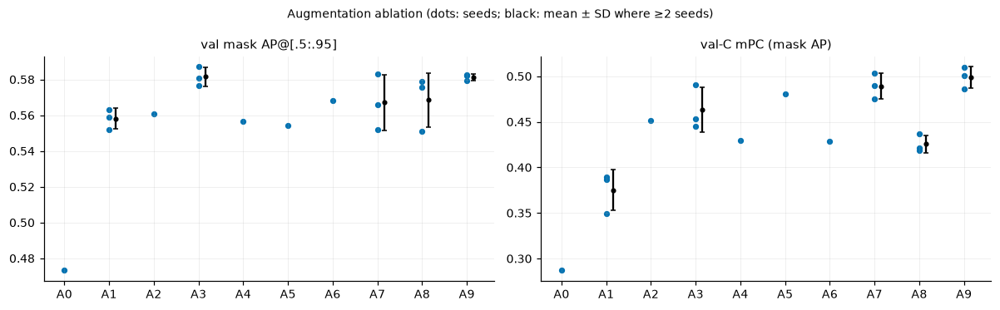

saved figure: outputs/02_preprocessing_augmentation/figures/fig04_learning_curves_seed42.png|pdf


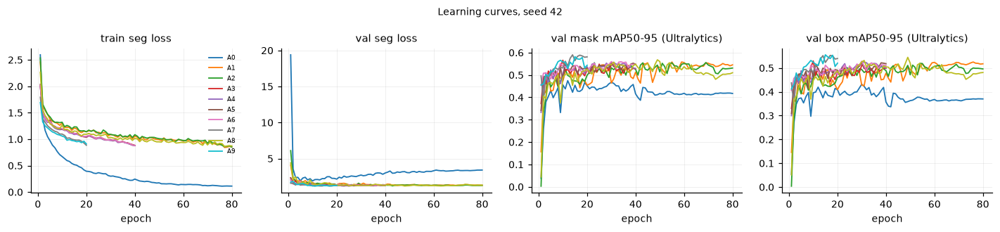

saved figure: outputs/02_preprocessing_augmentation/figures/fig05_robustness_by_severity.png|pdf


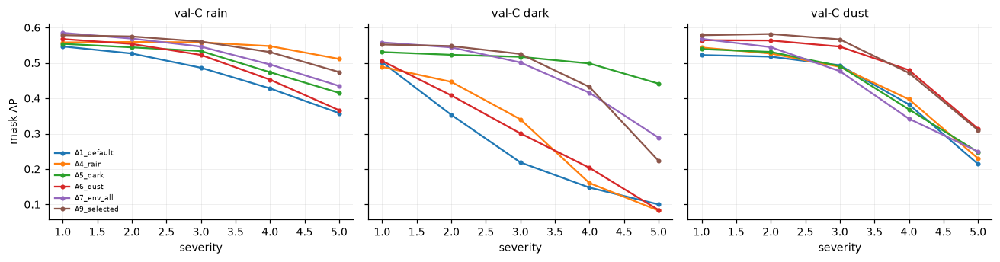

In [27]:
# รูปสรุปผลของ ablation
if RUN_TRAINING:
    ALL = pd.concat([SCREEN, CONF, A9]).drop_duplicates(["arm", "seed"])
    save_table(ALL.drop(columns=["state_thresholds"]), TAB / "augmentation_all_runs.csv")
    order = SCREEN_ORDER + ["A9_selected"]
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
    for k, (col, lab) in enumerate([("mask_AP", "val mask AP@[.5:.95]"), ("mPC_mask_AP", "val-C mPC (mask AP)")]):
        for i, arm in enumerate(order):
            v = ALL.loc[ALL.arm == arm, col]
            ax[k].scatter(np.full(len(v), i), v, s=14, color="#0072B2")
            if len(v) > 1:
                ax[k].errorbar(i + 0.15, v.mean(), yerr=v.std(ddof=1), fmt="o", color="#000000", ms=3, capsize=2)
        ax[k].set_xticks(range(len(order)), [a.split("_")[0] for a in order]); ax[k].set_title(lab)
    fig.suptitle("Augmentation ablation (dots: seeds; black: mean ± SD where ≥2 seeds)", fontsize=9)
    fig.tight_layout(); savefig(fig, FIG / "fig03_augmentation_ablation"); plt.show()
    plot_curves([RUNS[a][SEED] for a in order if SEED in RUNS[a]], [a.split("_")[0] for a in order if SEED in RUNS[a]],
                FIG / "fig04_learning_curves_seed42", "Learning curves, seed 42")
    rob = []
    for arm in ["A1_default"] + [a for a in ("A4_rain", "A5_dark", "A6_dust", "A7_env_all", "A9_selected") if a in RUNS]:
        f = Path(RUNS[arm][SEED]) / "eval" / "valC_clean.csv"
        if f.exists():
            rob.append(pd.read_csv(f).assign(arm=arm))
    if rob:
        R = pd.concat(rob)
        fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), sharey=True)
        for ax, scen in zip(axes, ["rain", "dark", "dust"]):
            for arm, d in R[R.scenario == scen].groupby("arm"):
                ax.plot(d.level, d.mask_AP, marker="o", ms=3, label=arm)
            ax.set_title(f"val-C {scen}"); ax.set_xlabel("severity")
        axes[0].set_ylabel("mask AP"); axes[0].legend(frameon=False, fontsize=6)
        fig.tight_layout(); savefig(fig, FIG / "fig05_robustness_by_severity"); plt.show()

## 9. การแบ่ง offline / online และการใช้กับแต่ละ split

| การแปลง | ประเภท | train | val | test / holdout |
|---|---|---|---|---|
| Letterbox 640 | preprocessing (ทุกขั้นตอน) | ใช้ | ใช้ | ใช้ |
| Preprocessing ที่ผ่านหัวข้อ 3 และ 7 (ถ้ามี) | preprocessing | ใช้ | ใช้ | ใช้ (บันทึกใน config ที่ตรึง) |
| ฝน / แสงน้อย / ฝุ่น / photometric (arm ที่เลือก) | offline augmentation | ใช้ | ไม่ใช้ | ไม่ใช้ |
| HSV, flip, rotate, translate, scale, mosaic, copy-paste | online augmentation | ใช้ | ไม่ใช้ | ไม่ใช้ |
| val-C | ชุดประเมินความทนทาน | — | ใช้เลือกวิธี | ไม่ใช้ |

## 10. สรุปผลของ Notebook 02

ส่วนนี้เขียนหลังจากรันการฝึกครบ โดยต้องอ้างตัวเลขจากตาราง `outputs/02_preprocessing_augmentation/tables/` เท่านั้น

- **RQ2 (preprocessing):** ดู `preprocessing_method_table.csv` และผลของ arm `P_*`
- **RQ3 (augmentation):** ดู `augmentation_confirmation_3seeds.csv`, `augmentation_decision.csv` และ `configs/aug_recipe_selected.json`
- **Shortlist สำหรับ Notebook 03:** สูตรที่เลือกใน `configs/aug_recipe_selected.json`